##### Master Degree in Computer Science and Data Science for Economics and Health

# LLMs in practice: choosing, running and evaluating a language model

### Sergio Picascia

## Introduction

In this notebook we take a real, recent open model and a real task, and we ask the questions that come before and after the model itself: which model to choose among thousands, whether it fits in memory, what it actually reads when we send it a message, how to get answers that a program can use, how fast it is, and how good it is at *our* task.

**The task.** We use MASSIVE (FitzGerald et al., 2023): requests to a voice assistant, written by people, each labeled with what the user wants, the *intent* (`alarm_set`, `weather_query`, `play_music`, ... 60 in all). The same requests have been translated into 50 other languages, so we can ask the same question in English and in Italian. The task is a classification, and this is on purpose: every answer is right or wrong, so we can measure everything we do.

**The models.** The Qwen3.5 family (Qwen Team, 2026), in the sizes that a laptop can run: 0.8, 2 and 4 billion parameters, plus the base (only pre-trained) version of the 2B. They are released under the Apache 2.0 licence and can be downloaded without registration. All the numbers in this notebook come from an Apple M2 Max with 32 GB of memory, with the `mps` device of PyTorch. The code also runs on an NVIDIA GPU (`cuda`) and, slowly, on the CPU.

The questions of this notebook:

1. **Step 1**: the task and the data. MASSIVE with the `datasets` library: splits, features, filters, and the same request in eight languages;
2. **Step 2**: choosing a model. What the name, the card and the configuration of a model tell us before we download it: size, base or instruct, dense or mixture of experts, licence, and how many tokens the same request costs in each language;
3. **Step 3**: loading a model, and what it costs in memory. `from_pretrained`, the weights in 32 and 16 bits, the memory needed to train, and the cache that grows with the text;
4. **Step 4**: fewer bits. Quantization by hand, on one matrix and on the whole model, and the formats that we find on the Hub;
5. **Step 5**: talking to a model. The chat template, the answer, base and instruct models, thinking, the rules of L1.4 to choose the next token on a real distribution, and a conversation that the model does not remember;
6. **Step 6**: answers that a program can read. JSON in the prompt, constrained decoding written by hand, and tools;
7. **Step 7**: many requests. Where the time goes, batches, and why the same request at temperature 0 can give different answers;
8. **Step 8**: evaluation. The public benchmarks and what they say, and our own measure, with confidence intervals: sizes, languages, base and instruct, bits, thinking.

Then come the limits of what we did, the conclusions, and three appendices: the same requests served by inference engines (llama.cpp, MLX, vLLM and others), sent to a paid API, and a reference for fine-tuning a model with the libraries.

In [1]:
import os
import re
import gc
import logging
import json
import math
import time
import platform
import warnings
from collections import Counter
from typing import Literal

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import datasets
import transformers
import huggingface_hub
from datasets import load_dataset
from huggingface_hub import HfApi
from pydantic import BaseModel, ValidationError
from transformers import AutoConfig, AutoTokenizer, AutoModelForCausalLM, GenerationConfig, TextStreamer
from transformers.utils import get_json_schema

warnings.filterwarnings("ignore", category=FutureWarning)
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)     # a note of PyTorch on macOS
transformers.logging.set_verbosity_error()        # only the errors of the library (see Step 3 for a warning that we hide)
transformers.logging.disable_progress_bar()
datasets.disable_progress_bars()
huggingface_hub.utils.disable_progress_bars()

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
CACHE = "../../models/L1.X"                  # outside the repository: the results of the long runs, saved only to save time
os.makedirs(CACHE, exist_ok=True)

def cached(name, compute):
    # the result saved in CACHE/name.json if the file exists; otherwise `compute()` runs and its result is saved there
    path = f"{CACHE}/{name}.json"
    if os.path.exists(path):
        with open(path) as f:
            result = json.load(f)
        print(f"{name}: loaded from the cache")
        return result
    start = time.time()
    result = compute()
    with open(path, "w") as f:
        json.dump(result, f)
    print(f"{name}: computed in {time.time() - start:.0f} s")
    return result

def release():
    # give back to the device the memory of the objects that we have deleted
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()

def synchronize():
    # wait until the device has finished its work, so that the times we measure are the real ones
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    elif DEVICE == "mps":
        torch.mps.synchronize()

def device_memory():
    # the bytes that PyTorch holds on the device
    return torch.mps.driver_allocated_memory() if DEVICE == "mps" else torch.cuda.memory_allocated() if DEVICE == "cuda" else 0

print(f"torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}; device: {DEVICE} ({platform.system()}, {platform.machine()})")

torch 2.15.0, transformers 5.23.0, datasets 5.2.0; device: mps (Darwin, arm64)


## Step 1: the task and the data

> **A simple example.** A voice assistant hears `wake me up at five am this week`. Before doing anything it has to decide what the user wants: to set an alarm, and not to ask which alarms are set or to remove one. The same request in Italian is `svegliami alle cinque di mattina questa settimana`, and the answer has to be the same.
>
> The question of this section is: what does such a task look like in real data, and how do we get the data into our program? The intuition is that a public dataset gives us many requests with the right answer written by people, so that we can *measure* a model instead of trying it on two examples, and that the `datasets` library gives us any dataset of the Hub with the same few lines.

In [2]:
massive = load_dataset("mteb/amazon_massive_intent", "en")      # the English part of MASSIVE, with its three splits
massive

DatasetDict({
    train: Dataset({
        features: ['id', 'label', 'label_text', 'text', 'lang'],
        num_rows: 11514
    })
    test: Dataset({
        features: ['id', 'label', 'label_text', 'text', 'lang'],
        num_rows: 2974
    })
    validation: Dataset({
        features: ['id', 'label', 'label_text', 'text', 'lang'],
        num_rows: 2033
    })
})

`load_dataset` downloads the files of the dataset the first time (here, three compressed JSON files), keeps them in a cache on the disk (`~/.cache/huggingface`), and returns a `DatasetDict`, a dictionary with one `Dataset` for each split. A `Dataset` is a table with typed columns (the `features`), stored on the disk in the Arrow format so that it does not have to fit in memory; each row is a dictionary.

A note on this copy of the data. MASSIVE (FitzGerald et al., 2023) was built from SLURP (Bastianelli et al., 2020), a collection of English requests to a home assistant, translated and localized by professional translators (the names of places, for example, are adapted to each country). Each request is labeled with a scenario, an intent and the *slots*, the pieces of the request that matter (`wake me up at [time : five am]`); we use only the intents. We load the copy that the MTEB benchmark (Muennighoff et al., 2023) made of it, which keeps the text, the intent and the identifier of each request. The licence of MASSIVE is CC BY 4.0: we can use it, citing it.

In [3]:
test = massive["test"]
print(test.features)
print(test[0])
test.select(range(5)).to_pandas()[["id", "text", "label"]]

{'id': Value('string'), 'label': Value('string'), 'label_text': Value('string'), 'text': Value('string'), 'lang': Value('string')}
{'id': '0', 'label': 'alarm_set', 'label_text': 'alarm_set', 'text': 'wake me up at five am this week', 'lang': 'en'}


,id,text,label
0,0,wake me up at five am this week,alarm_set
1,3,quiet,audio_volume_mute
2,8,pink is all we need,iot_hue_lightchange
3,14,and the darkness has fallen,iot_hue_lighton
4,19,olly turn the lights off in the bedroom,iot_hue_lightoff


In [4]:
LABELS = sorted(set(massive["train"]["label"]))                   # the intents, in alphabetical order
scenarios = {}
for label in LABELS:
    scenarios.setdefault(label.split("_")[0], []).append(label)  # the scenario is the first part of the name of the intent
counts = Counter(test["label"])
print(f"{len(LABELS)} intents in {len(scenarios)} scenarios; {len(massive['train']):,} requests for training, "
      f"{len(massive['validation']):,} for validation, {len(test):,} for test")
print(f"intents with no request in the test set: {sorted(set(LABELS) - set(counts))}")
print(f"the most frequent in the test set: {counts.most_common(3)}; the least frequent: {counts.most_common()[-3:]}\n")
for scenario, labels in scenarios.items():
    print(f"{scenario:15s} {', '.join(labels)}")

60 intents in 18 scenarios; 11,514 requests for training, 2,033 for validation, 2,974 for test
intents with no request in the test set: ['cooking_query']
the most frequent in the test set: [('calendar_set', 209), ('play_music', 176), ('general_quirky', 169)]; the least frequent: [('music_dislikeness', 4), ('iot_hue_lighton', 3), ('general_greet', 1)]

alarm           alarm_query, alarm_remove, alarm_set
audio           audio_volume_down, audio_volume_mute, audio_volume_other, audio_volume_up
calendar        calendar_query, calendar_remove, calendar_set
cooking         cooking_query, cooking_recipe
datetime        datetime_convert, datetime_query
email           email_addcontact, email_query, email_querycontact, email_sendemail
general         general_greet, general_joke, general_quirky
iot             iot_cleaning, iot_coffee, iot_hue_lightchange, iot_hue_lightdim, iot_hue_lightoff, iot_hue_lighton, iot_hue_lightup, iot_wemo_off, iot_wemo_on
lists           lists_createoradd, lists_que

There are 60 intents in 18 scenarios, and 11,514 requests for training, 2,033 for validation and 2,974 for test, in every language. The intents are not balanced: in the test set `calendar_set` has 209 requests, `general_greet` only one, and `cooking_query` none. The intents of the same scenario are close to each other (`alarm_query`, `alarm_remove`, `alarm_set`; nine intents for the devices of a smart home, `iot_*`), and the third most frequent, `general_quirky`, collects the requests that fit nowhere. The task is not trivial, even for a person.

In [5]:
alarms = test.filter(lambda row: row["label"].startswith("alarm_"))         # a new Dataset with the rows that satisfy a condition
with_length = test.map(lambda row: {"words": len(row["text"].split())})     # a new column, computed row by row
print(f"{len(alarms)} requests about alarms, for example {alarms['text'][:3]}")
print(f"words per request: {np.mean(with_length['words']):.1f} on average, {max(with_length['words'])} at most")

EVAL = test.shuffle(seed=0).select(range(500))         # the 500 requests on which we measure the models in the whole notebook
IDS, TEXTS, GOLD = list(EVAL["id"]), list(EVAL["text"]), list(EVAL["label"])
print(f"\n{len(EVAL)} requests to measure the models, with {len(set(GOLD))} different intents")

96 requests about alarms, for example ['wake me up at five am this week', 'cancel my seven am alarm', 'what alarms i have set']
words per request: 6.8 on average, 61 at most

500 requests to measure the models, with 55 different intents


`filter`, `map`, `shuffle` and `select` never change a dataset: they return a new one (and `map` keeps the result in the cache, so that the second time it is not computed again). The test set has 96 requests about alarms; a request has 6.8 words on average and 61 at most: short spoken commands, often without punctuation and with a wake word (`olly`). The 500 requests that we keep, chosen at random with a fixed seed, are the test of the whole notebook: every model and every setting will be measured on exactly these requests.

The dataset is parallel: a request has the same identifier in all the languages, so we can take the same 500 requests in Italian, and in six other languages chosen to have different scripts.

In [6]:
LANGUAGES = {"en": "English", "it": "Italian", "de": "German", "zh-CN": "Chinese", "ja": "Japanese", "ar": "Arabic", "hi": "Hindi", "am": "Amharic"}
by_id = {}
for language in LANGUAGES:
    split = test if language == "en" else load_dataset("mteb/amazon_massive_intent", language, split="test")
    by_id[language] = dict(zip(split["id"], split["text"]))          # identifier -> text of the request in that language
TEXTS_IT = [by_id["it"][i] for i in IDS]                            # the same 500 requests, in Italian
pd.DataFrame({name: [by_id[language][i] for i in IDS[:3]] for language, name in LANGUAGES.items()}, index=GOLD[:3]).T

,weather_query,weather_query,iot_hue_lightoff
English,will it rain tomorrow,will the temperature stay about the same or is...,turn office lights off
Italian,pioverà domani,la temperatura rimarrà la stessa o farà più fr...,spegni tutte le luci dell' ufficio
German,wird es morgen regnen,wird die temperatur gleich bleiben oder wird e...,schalte die büro lampen aus
Chinese,明天下雨吗,温度是会保持不变呢还是会更低,关掉办公室的灯
Japanese,明日は雨ですか,気温は同じくらいですか、それとも低くなりますか,オフィスの照明をオフにする
Arabic,تتوقع تمطر بكره,هل ستبقى درجة الحرارة كما هي تقريبًا أم ستزداد...,قم بإطفاء أضواء المكتب
Hindi,क्या कल वर्षा होगी,क्या तापमान लगभग समान रहेगा या यह ठंडा होने वा...,कार्यालय की बत्तियाँ बंद करें
Amharic,ነገ ዝናብ ይዘንባል,የሙቀት መጠኑ እንደዚያው ይቆያል ወይንስ እየቀዘቀዘ ይሄዳል,የቢሮ መብራቶች አጥፋ


## Step 2: choosing a model

> **A simple example.** We look for a model that reads `svegliami alle cinque di mattina questa settimana` and answers `alarm_set`. On the Hub the candidates have names such as `Qwen3.5-2B`, `Qwen3.5-2B-Base`, `Qwen3.5-35B-A3B-FP8`, `gemma-4-E2B-it`, `gpt-oss-20b` or `Ministral-3-3B-Instruct-2512`, and each one comes with a page of text, the *model card*. Before we download a single weight we would like to know how big the model is, what it was trained to do, whether we are allowed to use it, and how well it reads Italian.
>
> The question of this section is: what can we know about a model before running it? The intuition is that the name, the card and two small files, the configuration and the tokenizer, already say most of what we need to make a short list. What they cannot say is how well a model does *our* task: we measure that in Step 8.

In [7]:
api = HfApi()
CANDIDATES = ["Qwen/Qwen3.5-0.8B", "Qwen/Qwen3.5-2B", "Qwen/Qwen3.5-2B-Base", "Qwen/Qwen3.5-4B", "Qwen/Qwen3.5-27B",
              "Qwen/Qwen3.5-35B-A3B", "Qwen/Qwen3.5-35B-A3B-FP8", "google/gemma-4-E2B-it", "openai/gpt-oss-20b",
              "mistralai/Ministral-3-3B-Instruct-2512", "HuggingFaceTB/SmolLM3-3B", "allenai/Olmo-3-7B-Instruct",
              "sapienzanlp/Minerva-7B-instruct-v1.0", "meta-llama/Llama-3.1-8B-Instruct"]
rows = []
for name in CANDIDATES:
    info = api.model_info(name)                          # the metadata of the repository: no weight is downloaded
    rows.append({"repository": name, "parameters (billions)": info.safetensors.total / 1e9 if info.safetensors else float("nan"),
                 "licence": getattr(info.card_data, "license", None), "access": f"gated ({info.gated})" if info.gated else "open",
                 "created": str(info.created_at.date()), "task on the Hub": info.pipeline_tag, "downloads (last 30 days)": info.downloads})
pd.DataFrame(rows).style.format({"parameters (billions)": "{:.2f}", "downloads (last 30 days)": "{:,}"}).hide(axis="index")

repository,parameters (billions),licence,access,created,task on the Hub,downloads (last 30 days)
Qwen/Qwen3.5-0.8B,0.87,apache-2.0,open,2026-02-28,image-text-to-text,"2,900,659"
Qwen/Qwen3.5-2B,2.27,apache-2.0,open,2026-02-28,image-text-to-text,"4,915,024"
Qwen/Qwen3.5-2B-Base,2.27,apache-2.0,open,2026-02-28,image-text-to-text,"330,631"
Qwen/Qwen3.5-4B,4.66,apache-2.0,open,2026-02-27,image-text-to-text,"4,824,135"
Qwen/Qwen3.5-27B,27.78,apache-2.0,open,2026-02-24,image-text-to-text,"1,678,738"
Qwen/Qwen3.5-35B-A3B,35.95,apache-2.0,open,2026-02-24,image-text-to-text,"1,442,510"
Qwen/Qwen3.5-35B-A3B-FP8,35.95,apache-2.0,open,2026-02-25,image-text-to-text,"933,915"
google/gemma-4-E2B-it,5.12,apache-2.0,open,2026-03-02,any-to-any,"2,866,213"
openai/gpt-oss-20b,20.91,apache-2.0,open,2025-08-04,text-generation,"5,575,731"
mistralai/Ministral-3-3B-Instruct-2512,3.85,apache-2.0,open,2025-10-31,None,"70,539"


The table comes from the metadata of the Hub, read without downloading anything (the downloads are those of the last 30 days, on the day we ran the cell). How to read the names:

* **The family and its version**: `Qwen3.5`, `gemma-4`, `Olmo-3`, `Ministral-3`. Within a family the models share the tokenizer, the training recipe and often the chat template, but not always (Step 5).
* **The size**: `0.8B`, `2B`, `27B` are billions of parameters. The table also counts the parameters of the image encoder, because the Qwen3.5 and Gemma 4 models read images too: Qwen3.5-2B has 2.27 billion parameters in its files. `E2B` (Gemma 4) is another convention: 2.3 billion *effective* parameters for 5.1 billion in the files, because each layer has its own embedding table, which costs memory but not computation (see the card).
* **What the model was trained to do**: `-Base` is the pre-trained model of L1.6 (Step 1), which continues texts; `-Instruct`, `-it`, or no suffix in the Qwen3.5 family, the model after instruction tuning and preference tuning (L1.6, Steps 3-6); `-Thinking` or `-Reasoning`, a model trained to write a reasoning before the answer (Step 5).
* **`A3B`**: a *mixture of experts* with 3 billion parameters *active* for each token (below).
* **The format of the weights**: `-FP8`, `-GPTQ-Int4`, `-AWQ`, `-GGUF`, `-4bit` are the same model stored with fewer bits (Step 4), often in the repository of someone else (`unsloth`, `bartowski`, `mlx-community`, `lmstudio-community`); `2512` is a date (December 2025).

**The licence** decides what we can do with the weights. There are three groups:

* **closed models**, which we can only use through the API of their company (GPT, Claude, Gemini: Appendix B). We never see the weights;
* **open weights**: we can download and run the weights, under a licence that can be a standard one (Apache 2.0 for Qwen3.5, Gemma 4, gpt-oss, Ministral 3) or a licence of the company: Llama 3.1 has its own *community licence* with an acceptable-use policy, and its repository is *gated* (`manual`: a person approves the request to download it);
* **fully open** models, which also publish the training data and code, so that the training can be studied and repeated: OLMo 3 (Ai2) and SmolLM3 (Hugging Face) in the table. The Open Source Initiative published in October 2024 a definition of *open-source AI* that asks for this: the weights alone are not enough to call a model open source.

Minerva (Sapienza University of Rome) was trained from scratch on Italian and English. The licence of the *data* counts too: MASSIVE is CC BY 4.0.

In [8]:
def text_config(name):
    # the configuration of the language model (the multimodal models keep it in `text_config`): only config.json is downloaded
    config = AutoConfig.from_pretrained(name)
    return getattr(config, "text_config", None) or config

dense, moe = text_config("Qwen/Qwen3.5-2B"), text_config("Qwen/Qwen3.5-35B-A3B")
print("Qwen3.5-2B, the kinds of layer:     ", dict(Counter(dense.layer_types)))
print("Qwen3.5-35B-A3B, the kinds of layer:", dict(Counter(moe.layer_types)))

expert = 3 * moe.hidden_size * moe.moe_intermediate_size              # an expert is a small MLP with three matrices (L1.1)
routed = moe.num_hidden_layers * moe.num_experts * expert              # the parameters of all the experts that are chosen by the router
total = api.model_info("Qwen/Qwen3.5-35B-A3B").safetensors.total
print(f"\n{moe.num_experts} experts in each of the {moe.num_hidden_layers} layers, {moe.num_experts_per_tok} chosen for each token, plus one expert shared by all tokens")
print(f"the experts that can be chosen hold {routed / 1e9:.1f} of the {total / 1e9:.1f} billion parameters ({routed / total:.0%});")
print(f"for each token the model uses {moe.num_experts_per_tok} of them in each layer, {moe.num_hidden_layers * moe.num_experts_per_tok * expert / 1e9:.2f} billion parameters")

Qwen3.5-2B, the kinds of layer:      {'linear_attention': 18, 'full_attention': 6}
Qwen3.5-35B-A3B, the kinds of layer: {'linear_attention': 30, 'full_attention': 10}

256 experts in each of the 40 layers, 8 chosen for each token, plus one expert shared by all tokens
the experts that can be chosen hold 32.2 of the 36.0 billion parameters (90%);
for each token the model uses 8 of them in each layer, 1.01 billion parameters


Two architectural choices that we find in the names and in the configurations.

**Dense or mixture of experts (MoE).** In a dense model every token goes through all the parameters. In a mixture of experts the MLP of each block (L1.1) is replaced by many small MLPs, the *experts*, and a small network, the *router*, chooses a few of them for each token. Qwen3.5-35B-A3B has 256 experts in each of its 40 layers and chooses 8 of them for each token, plus one expert that every token uses. The 10,240 experts that can be chosen hold 32.2 of the 36.0 billion parameters of the model (90%), and a token goes through 1.01 billion of them. The consequence is practical: the memory needed is that of a 35-billion-parameter model (all the experts must be ready, because the next token may choose any of them), while the computation for each token is that of a model of about 3 billion parameters (the card counts 3 billion activated parameters, attention and shared expert included). This is why `35B-A3B` is fast, but needs a machine with a lot of memory.

**Full attention or not.** The configuration of Qwen3.5-2B says that only 6 of its 24 layers have the attention of L1.0; the other 18 are *linear-attention* layers (Gated DeltaNet, Yang et al., 2025), which keep a summary of fixed size of the past instead of the keys and values of every token. This matters for the memory of long texts, as we see in Step 3.

**Languages.** A model is trained on a mix of languages, and its tokenizer is trained on the same mix: a language that was rare in that mix is cut into more, shorter tokens. Every token costs computation, memory in the cache (Step 3), and money when we pay an API by the token (Appendix B). We count the tokens of the same 500 requests in the eight languages of Step 1, with five tokenizers; only the files of the tokenizers are downloaded.

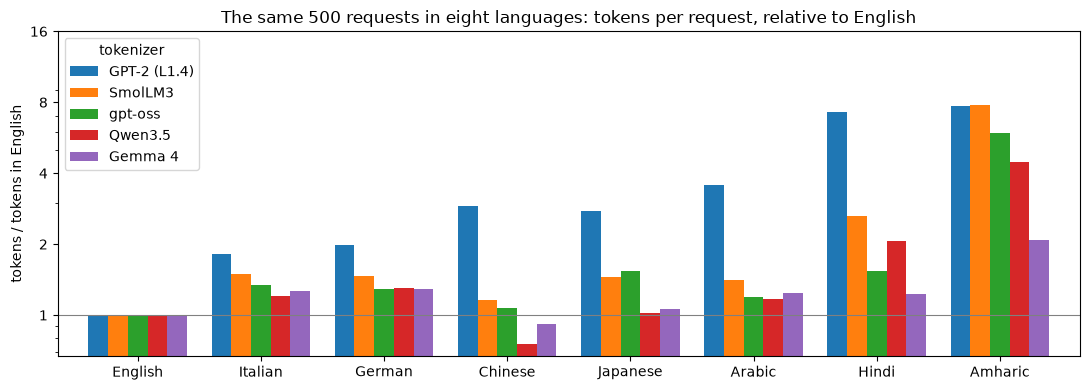

,vocabulary,English,Italian,German,Chinese,Japanese,Arabic,Hindi,Amharic
tokenizer,,,,,,,,,
GPT-2 (L1.4),"50,257",7.5,13.5,14.9,21.8,20.7,26.7,54.6,57.5
SmolLM3,"128,256",7.3,10.8,10.7,8.4,10.5,10.2,19.2,56.8
gpt-oss,"200,019",7.2,9.7,9.3,7.7,11.1,8.6,11.1,42.9
Qwen3.5,"248,077",7.3,8.8,9.5,5.5,7.4,8.5,15.0,32.5
Gemma 4,"262,144",7.3,9.1,9.4,6.7,7.7,9.0,8.9,15.1


In [9]:
TOKENIZERS = {"GPT-2 (L1.4)": "gpt2", "SmolLM3": "HuggingFaceTB/SmolLM3-3B", "gpt-oss": "openai/gpt-oss-20b",
              "Qwen3.5": "Qwen/Qwen3.5-2B", "Gemma 4": "google/gemma-4-E2B-it"}
rows = []
for label, repo in TOKENIZERS.items():
    tok = AutoTokenizer.from_pretrained(repo)
    row = {"tokenizer": label, "vocabulary": len(tok)}
    for language, name in LANGUAGES.items():
        row[name] = np.mean([len(tok(by_id[language][i], add_special_tokens=False).input_ids) for i in IDS])
    rows.append(row)
fertility = pd.DataFrame(rows).set_index("tokenizer")
ratio = fertility[list(LANGUAGES.values())].div(fertility["English"], axis=0)

ax = ratio.T.plot.bar(figsize=(11, 4), width=0.8)
ax.axhline(1, color="gray", lw=0.8)
ax.set_yscale("log")
ax.set_yticks([1, 2, 4, 8, 16]); ax.set_yticklabels(["1", "2", "4", "8", "16"])
ax.set_ylabel("tokens / tokens in English")
ax.set_title("The same 500 requests in eight languages: tokens per request, relative to English")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
fertility.style.format({**{name: "{:.1f}" for name in LANGUAGES.values()}, "vocabulary": "{:,}"})

An English request is about 7.2 to 7.5 tokens with every tokenizer, but the other languages are not equal. An Italian request costs 1.21 times the English one with Qwen3.5 (8.8 tokens against 7.3) and 1.81 times with GPT-2, whose tokenizer was trained almost only on English (L1.4). Chinese costs *fewer* tokens than English with Qwen3.5 (0.75 times), whose vocabulary contains many Chinese words, and 2.9 times with GPT-2. Hindi and Amharic, written in scripts that are rare on the web, cost 7 to 8 times English with GPT-2, and Amharic as much with SmolLM3; Gemma 4, with the largest vocabulary (262,144 tokens) and more than 140 languages in its training, keeps Hindi at 1.23 and Amharic at 2.1 times. A user who writes in Amharic to Qwen3.5 pays 4.5 times the tokens of an English user for the same request, and fits 4.5 times less text in the same context. Before choosing a model for a language, count its tokens on that language.

## Step 3: loading a model, and what it costs in memory

> **A simple example.** Qwen3.5-2B has 1.88 billion parameters in its language model. Stored in 16 bits, 2 bytes each, they take about 3.8 GB; in 32 bits, twice as much. A laptop with 32 GB can hold them. To *train* all of them we need much more, and while the model writes, every token adds keys and values to the cache (L1.4, Step 9).
>
> The question of this section is: how much memory does a model need to run and to train, and what grows with the length of the text? The intuition is that the weights cost the number of parameters times the bytes of each one; that training multiplies this by eight, before counting the activations; and that the cache grows with the number of tokens and, in a long text, can become larger than the weights.

We load the model as in L1.3 (Step 5) and L1.4 (Step 10), with the `Auto` classes of `transformers`, which read the configuration and build the right class. The type of the numbers is given with `dtype`, whose default, `"auto"`, is the type in which the weights are stored. `device_map` puts the model on the device. First the tokenizer.

In [10]:
NAME = "Qwen/Qwen3.5-2B"
tokenizer = AutoTokenizer.from_pretrained(NAME, padding_side="left")       # padding on the left, to write in batches (Step 7)
encoded = tokenizer(TEXTS[0])
print(TEXTS[0])
print(encoded)
print(tokenizer.convert_ids_to_tokens(encoded["input_ids"]))
print(f"\nvocabulary: {len(tokenizer):,} tokens; the end of a turn: {tokenizer.eos_token!r} ({tokenizer.eos_token_id}); "
      f"padding: {tokenizer.pad_token!r} ({tokenizer.pad_token_id})")

will it rain tomorrow
{'input_ids': [13974, 424, 10849, 16089], 'attention_mask': [1, 1, 1, 1]}
['will', 'Ġit', 'Ġrain', 'Ġtomorrow']

vocabulary: 248,077 tokens; the end of a turn: '<|im_end|>' (248046); padding: '<|endoftext|>' (248044)


In [11]:
release()
memory_before = device_memory()
start = time.time()
model = AutoModelForCausalLM.from_pretrained(NAME, device_map=DEVICE).eval()     # dtype="auto": the type of the stored weights
print(f"{type(model).__name__} loaded in {time.time() - start:.1f} s: dtype {model.dtype}, device {model.device}, "
      f"attention implementation {model.config._attn_implementation!r}")
config = model.config
n_parameters = sum(p.numel() for p in model.parameters())
n_embedding = model.get_input_embeddings().weight.numel()
pd.Series({"blocks": f"{config.num_hidden_layers} {dict(Counter(config.layer_types))}",
           "d (width of the residual stream)": config.hidden_size,
           "query heads / key-value heads": f"{config.num_attention_heads} / {config.num_key_value_heads}",
           "size of a head": config.head_dim, "width of the MLP": config.intermediate_size,
           "vocabulary": f"{config.vocab_size:,}", "positions": f"{config.max_position_embeddings:,}",
           "the output layer is the embedding table": config.tie_word_embeddings,
           "parameters": f"{n_parameters:,}", "of which the embedding table": f"{n_embedding:,} ({n_embedding / n_parameters:.0%})"},
          name=NAME).to_frame()

Qwen3_5ForCausalLM loaded in 1.1 s: dtype torch.bfloat16, device mps:0, attention implementation 'sdpa'


,Qwen/Qwen3.5-2B
blocks,"24 {'linear_attention': 18, 'full_attention': 6}"
d (width of the residual stream),2048
query heads / key-value heads,8 / 2
size of a head,256
width of the MLP,6144
vocabulary,"248,320"
positions,"262,144"
the output layer is the embedding table,True
parameters,"1,881,825,088"
of which the embedding table,"508,559,360 (27%)"


`AutoModelForCausalLM` built `Qwen3_5ForCausalLM`, the language model alone: the files also contain the encoder of images, which this class does not load (`AutoModelForImageTextToText` would), so we have 1.88 billion parameters and not the 2.27 of the table of Step 2. The weights are in `bfloat16`, the type in which they are stored. The vocabulary of 248,320 rows (the 248,077 tokens of the tokenizer, padded to a round number) makes the embedding table large: 509 million numbers, 27% of the model; it is also the output layer (`tie_word_embeddings`), as in GPT-2. In a small model with a large vocabulary a quarter of the parameters are there to read and write tokens.

In [12]:
footprint = model.get_memory_footprint()                 # the bytes of the parameters and buffers of the model
print(f"16 bits: {n_parameters:,} parameters x 2 bytes = {2 * n_parameters / 1e9:.2f} GB; get_memory_footprint() = {footprint / 1e9:.2f} GB; "
      f"memory taken on the device: {(device_memory() - memory_before) / 1e9:.2f} GB")
model32 = AutoModelForCausalLM.from_pretrained(NAME, dtype=torch.float32, device_map=DEVICE)
print(f"32 bits: {n_parameters:,} parameters x 4 bytes = {4 * n_parameters / 1e9:.2f} GB; get_memory_footprint() = {model32.get_memory_footprint() / 1e9:.2f} GB")
del model32
release()

16 bits: 1,881,825,088 parameters x 2 bytes = 3.76 GB; get_memory_footprint() = 3.76 GB; memory taken on the device: 3.77 GB
32 bits: 1,881,825,088 parameters x 4 bytes = 7.53 GB; get_memory_footprint() = 7.53 GB


In 16 bits the model takes 3.76 GB, exactly 1,881,825,088 × 2 bytes, and the device holds 3.77 GB for it; in 32 bits it takes 7.53 GB. The rule *parameters times bytes* is exact for the weights.

**Training needs much more.** To train all the weights with Adam in mixed precision (the usual way), for each parameter we keep the weight in 16 bits (2 bytes), its gradient in 16 bits (2), a copy of the weight in 32 bits for the update (4) and the two averages of Adam in 32 bits (4 + 4): **16 bytes per parameter**, eight times the weights, before counting the *activations*, the outputs of every layer kept for the backward pass, which grow with the batch and the length of the texts (Rajbhandari et al., 2020). This is the cost that L1.5 attributed to the full fine-tuning; with LoRA the weights are frozen and only the adapters, a small fraction, need gradients and Adam; with QLoRA the frozen weights are stored in 4 bits (Dettmers et al., 2023). The table is arithmetic, not a measure: it counts only the parameters.

In [13]:
BYTES = {"inference, 16 bits": 2, "inference, 4 bits (+ scales, Step 4)": 0.56, "full fine-tuning (Adam, mixed precision)": 16,
         "LoRA (frozen weights in 16 bits)": 2, "QLoRA (frozen weights in 4 bits)": 0.56}
SIZES = {"0.8B": 0.8e9, "2B": 2e9, "4B": 4e9, "9B": 9e9, "27B": 27e9, "70B": 70e9}
pd.DataFrame({size: {use: n * b / 1e9 for use, b in BYTES.items()} for size, n in SIZES.items()}).style.format("{:,.1f} GB")

,0.8B,2B,4B,9B,27B,70B
"inference, 16 bits",1.6 GB,4.0 GB,8.0 GB,18.0 GB,54.0 GB,140.0 GB
"inference, 4 bits (+ scales, Step 4)",0.4 GB,1.1 GB,2.2 GB,5.0 GB,15.1 GB,39.2 GB
"full fine-tuning (Adam, mixed precision)",12.8 GB,32.0 GB,64.0 GB,144.0 GB,432.0 GB,"1,120.0 GB"
LoRA (frozen weights in 16 bits),1.6 GB,4.0 GB,8.0 GB,18.0 GB,54.0 GB,140.0 GB
QLoRA (frozen weights in 4 bits),0.4 GB,1.1 GB,2.2 GB,5.0 GB,15.1 GB,39.2 GB


**The cache.** In L1.4 (Step 9) the cache of a text kept, for each block, the keys and the values of every token: $2 \times \text{blocks} \times \text{tokens} \times d$ numbers. Real models changed this count in three ways, and the configuration tells us which:

* **grouped-query attention** (GQA, Ainslie et al., 2023): many query heads share the same key and value heads, so a token stores $2 \times \text{key-value heads} \times \text{head size}$ numbers per layer, fewer than $2d$. Qwen3.5-2B has 8 query heads and 2 key-value heads;
* **sliding windows**: some layers attend only to the last few tokens (128 in gpt-oss), and keep only those;
* **layers without keys and values**: the linear-attention layers of Qwen3.5 keep a state of fixed size, whatever the length of the text.

So the bytes for each token are $2 \times (\text{layers that keep every token}) \times \text{key-value heads} \times \text{head size} \times \text{bytes per number}$. We compute them from the configuration of seven models, without downloading their weights.

In [14]:
def cache_bytes_for(config, tokens, bytes_per_number=2):
    # bytes of the keys and values of a text of `tokens` tokens: the full-attention layers keep every token, the sliding-window
    # layers only the last `sliding_window`, the linear-attention layers none (their state does not grow with the text)
    types = getattr(config, "layer_types", None) or ["full_attention"] * config.num_hidden_layers
    head_dim = getattr(config, "head_dim", None) or config.hidden_size // config.num_attention_heads
    kept = sum(tokens if t == "full_attention" else min(tokens, config.sliding_window) if t == "sliding_attention" else 0 for t in types)
    return 2 * config.num_key_value_heads * head_dim * bytes_per_number * kept

KV_MODELS = ["Qwen/Qwen3-1.7B", "Qwen/Qwen3.5-2B", "HuggingFaceTB/SmolLM3-3B", "Qwen/Qwen3-8B", "openai/gpt-oss-20b", "Qwen/Qwen3.5-27B", "Qwen/Qwen3.5-35B-A3B"]
configs = {name: text_config(name) for name in KV_MODELS}
rows = []
for name, c in configs.items():
    weights = sum(s.size for s in api.model_info(name, files_metadata=True).siblings if s.rfilename.endswith(".safetensors") and "/" not in s.rfilename)
    types = getattr(c, "layer_types", None) or ["full_attention"] * c.num_hidden_layers
    per_token = cache_bytes_for(c, 1_000_000) / 1_000_000
    rows.append({"model": name.split("/")[1], "layers": c.num_hidden_layers, "of which keep every token": sum(t == "full_attention" for t in types),
                 "KiB per token": per_token / 1024, "cache at 32K tokens (GB)": cache_bytes_for(c, 32_768) / 1e9,
                 "longest context": c.max_position_embeddings, "cache at the longest (GB)": cache_bytes_for(c, c.max_position_embeddings) / 1e9,
                 "weights on the Hub (GB)": weights / 1e9, "tokens at which the cache equals the weights": weights / per_token})
pd.DataFrame(rows).style.format({"KiB per token": "{:.0f}", "cache at 32K tokens (GB)": "{:.1f}", "longest context": "{:,}",
                                 "cache at the longest (GB)": "{:.1f}", "weights on the Hub (GB)": "{:.1f}",
                                 "tokens at which the cache equals the weights": "{:,.0f}"}).hide(axis="index")

model,layers,of which keep every token,KiB per token,cache at 32K tokens (GB),longest context,cache at the longest (GB),weights on the Hub (GB),tokens at which the cache equals the weights
Qwen3-1.7B,28,28,112,3.8,"40,960",4.7,4.1,"35,431"
Qwen3.5-2B,24,6,12,0.4,"262,144",3.2,4.5,"370,135"
SmolLM3-3B,36,36,72,2.4,"65,536",4.8,6.2,"83,418"
Qwen3-8B,36,36,144,4.8,"40,960",6.0,16.4,"111,094"
gpt-oss-20b,24,12,24,0.8,"131,072",3.2,13.8,"559,878"
Qwen3.5-27B,64,16,64,2.1,"262,144",17.2,55.6,"847,824"
Qwen3.5-35B-A3B,40,10,20,0.7,"262,144",5.4,71.9,"3,510,932"


Qwen3-1.7B, a dense model of the previous generation, keeps 112 KiB for each token: at 32K tokens its cache is 3.8 GB, almost as large as its weights (4.1 GB), which it equals at about 35,000 tokens. Qwen3.5-2B, of about the same size, keeps 12 KiB, nine times less, because only 6 of its 24 layers keep keys and values, with 2 key-value heads each: at its longest context, 262,144 tokens, its cache is 3.2 GB, still less than its weights. Qwen3-8B keeps 144 KiB per token (4.8 GB at 32K); gpt-oss-20b, which has a window of 128 tokens in half of its layers, keeps 24 KiB; the larger Qwen3.5 models keep 64 KiB (27B) and 20 KiB (35B-A3B). And the cache is for each text: a server that writes for 32 users at the same time keeps 32 caches. We check the formula on the model we loaded: it reads texts of 1,000, 4,000 and 16,000 tokens, and we measure the bytes that its cache holds (the tokens are random: for memory and time only the length counts).

In [15]:
def cache_bytes(cache):
    # the bytes of a transformers cache: keys and values (they grow with the text) and states of the linear-attention layers (they do not)
    growing, fixed = 0, 0
    for layer in cache.layers:
        for name, value in vars(layer).items():
            for t in (value.values() if isinstance(value, dict) else [value]):
                if torch.is_tensor(t):
                    if name in ("keys", "values"):
                        growing += t.numel() * t.element_size()
                    else:
                        fixed += t.numel() * t.element_size()
    return growing, fixed

rows = []
for n in (1_000, 4_000, 16_000):
    ids = torch.randint(1_000, 100_000, (1, n), device=DEVICE)
    synchronize(); start = time.time()
    with torch.no_grad():
        out = model(input_ids=ids, use_cache=True, logits_to_keep=1)
    synchronize()
    growing, fixed = cache_bytes(out.past_key_values)
    rows.append({"tokens": n, "seconds to read them": time.time() - start, "keys and values (MiB)": growing / 2**20,
                 "the formula (MiB)": cache_bytes_for(config, n) / 2**20, "states of the linear-attention layers (MiB)": fixed / 2**20})
    del out
    release()
pd.DataFrame(rows).style.format({"tokens": "{:,}", "seconds to read them": "{:.1f}", "keys and values (MiB)": "{:.1f}",
                                 "the formula (MiB)": "{:.1f}", "states of the linear-attention layers (MiB)": "{:.1f}"}).hide(axis="index")

tokens,seconds to read them,keys and values (MiB),the formula (MiB),states of the linear-attention layers (MiB)
"1,000",0.7,11.7,11.7,18.8
"4,000",2.5,46.9,46.9,18.8
"16,000",11.3,187.5,187.5,18.8


The keys and values in the cache are exactly those of the formula (11.7 MiB for 1,000 tokens, 187.5 MiB for 16,000), and the 18 linear-attention layers keep 18.8 MiB whatever the length of the text: about 1 MiB each, a matrix of 16 heads × 128 × 128 numbers in 32 bits. Reading 16,000 tokens took 11.3 seconds on our machine.

**The length of the context.** The configuration says 262,144 positions, and the card says that the model can be extended to about one million. This is the length that the model *accepts*, not the length that it *uses* well. When a test hides a piece of information in a long text and asks for it, or asks to combine several pieces, models often get worse long before their maximum length (RULER, Hsieh et al., 2024), and a fact in the middle of a long context is used less than one at the beginning or at the end (Liu et al., 2024).

**How the attention is computed.** The model printed `attention implementation 'sdpa'`: the attention of the full-attention layers is computed by `scaled_dot_product_attention` of PyTorch, which chooses the fastest kernel for the device. FlashAttention (Dao et al., 2022; Dao, 2023), which you will find in many examples (`attn_implementation="flash_attention_2"`), computes *exactly* the same attention in blocks that fit in the fast memory of the GPU, without ever writing the whole $n \times n$ matrix of the scores: the memory grows linearly with the length instead of quadratically, while the number of operations is the same. It needs an NVIDIA GPU and the `flash-attn` package, so on a Mac that argument gives an error. The linear-attention layers are another matter: on NVIDIA GPUs `transformers` uses optimized kernels for them (the `flash-linear-attention` and `causal-conv1d` packages); on a Mac it uses a reference implementation in PyTorch, correct and slower, and warns about it (the warning is hidden in this notebook by `set_verbosity_error`).

## Step 4: fewer bits

> **A simple example.** A weight of the model, say $0.0213$, is stored in 16 bits. With 4 bits we can write only 15 values, the integers from $-7$ to $7$, so we write $w \approx q \times s$, with $q$ an integer and $s$ a *scale* shared by many weights. If the weights that share $s$ go from $-0.08$ to $0.08$, then $s = 0.08 / 7 \approx 0.011$ and $0.0213$ becomes $2 \times 0.011 = 0.023$: a small error. If one of them is $0.9$, then $s = 0.9 / 7 \approx 0.13$, and every weight smaller than $0.064$ becomes $0$.
>
> The question of this section is: how many bits does a weight need, and how do the formats that we find on the Hub keep the error small? The intuition is that the error depends on the range of the numbers that share a scale: the fewer numbers share a scale, the smaller the range and the error, and the more scales we have to store.

In [16]:
def quantize(w, bits, group):
    # round-to-nearest with 2^bits - 1 levels, symmetric around 0. Every `group` consecutive numbers of a row share a scale, the largest
    # |w| of the group divided by the largest level (group = length of a row: one scale per row; group = w.numel(): one scale for the
    # whole matrix). Returns the matrix rebuilt from the integers and the scales, the numbers the model will compute with
    levels = 2 ** (bits - 1) - 1                      # e.g. 7 for 4 bits: the integers from -7 to 7
    x = w.float().reshape(-1, group)
    scale = x.abs().amax(dim=1, keepdim=True).clamp(min=1e-12) / levels
    return (torch.round(x / scale).clamp(-levels, levels) * scale).reshape(w.shape).to(w.dtype)

W = model.model.layers[12].mlp.down_proj.weight.detach()             # one matrix of the MLP of block 12
w = W.float()
print(f"shape {tuple(W.shape)}; standard deviation {w.std():.4f}; largest |w| {w.abs().max():.3f}, that is {w.abs().max() / w.std():.0f} standard deviations; "
      f"{(w.abs() > 6 * w.std()).sum().item():,} weights of {w.numel():,} are beyond 6 standard deviations")

SCHEMES = {"one scale for the matrix": W.numel(), "one scale per row": W.shape[1], "groups of 128": 128, "groups of 64": 64, "groups of 32": 32}
rows = []
for scheme, group in SCHEMES.items():
    row = {"scale shared by": scheme, "bits per weight at 4 bits (scales in 16 bits)": 4 + 16 / group}
    for bits in (8, 4, 3, 2):
        row[f"error, {bits} bits"] = ((quantize(W, bits, group).float() - w).norm() / w.norm()).item()
    row["weights that become 0 at 4 bits"] = (quantize(W, 4, group) == 0).float().mean().item()
    rows.append(row)
pd.DataFrame(rows).style.format({"bits per weight at 4 bits (scales in 16 bits)": "{:.2f}", "weights that become 0 at 4 bits": "{:.1%}",
                                 **{f"error, {b} bits": "{:.3f}" for b in (8, 4, 3, 2)}}).hide(axis="index")

shape (2048, 6144); standard deviation 0.0084; largest |w| 0.188, that is 22 standard deviations; 400 weights of 12,582,912 are beyond 6 standard deviations


scale shared by,bits per weight at 4 bits (scales in 16 bits),"error, 8 bits","error, 4 bits","error, 3 bits","error, 2 bits",weights that become 0 at 4 bits
one scale for the matrix,4.00,0.051,0.803,0.996,1.000,88.9%
one scale per row,4.00,0.011,0.190,0.434,0.936,28.0%
groups of 128,4.12,0.007,0.125,0.291,0.779,17.8%
groups of 64,4.25,0.006,0.113,0.264,0.727,16.1%
groups of 32,4.50,0.006,0.101,0.235,0.664,14.3%


The function is the whole of *round-to-nearest* quantization: a scale for each group, the weights divided by the scale and rounded to an integer, and, to use the matrix, the integers multiplied back by the scale. The error in the table is relative, $\|W - Q(W)\| / \|W\|$.

The matrix has a standard deviation of 0.0084, and its largest weight is 0.188, 22 standard deviations away: only 400 of its 12.6 million weights are beyond 6 standard deviations, but each of them decides the scale of its group. With one scale for the whole matrix, the step of 4 bits is $0.188 / 7 \approx 0.027$, three times the standard deviation: 88.9% of the weights become 0, and the error is 80% of the norm of the matrix (the same scheme with 8 bits is fine: 5%). With one scale per row the error at 4 bits falls to 19%, and with groups of 64, the size used by MLX, to 11%; 16% of the weights still become 0, the ones that are really close to 0. Smaller groups cost more scales: 4 bits with a 16-bit scale for every 32 numbers are 4.5 bits per weight. At 3 and 2 bits even groups of 32 leave errors of 24% and 66%.

The real formats differ from our function in the details: the levels can be asymmetric (a scale and a minimum for each group, as in MLX), not uniform (NF4, whose 16 levels follow the bell shape of the weights, Dettmers et al., 2023), or chosen layer by layer with more bits where the error costs more. But the trade-off is the one of the table. What a matrix tells us is not yet what the model does: we now round **every** matrix of the 24 blocks and measure the model on a text, WikiText-2 (Merity et al., 2017), which is the standard of the papers on quantization. The embedding table, which is also the output layer, is left in 16 bits, as most formats do.

In [17]:
LINEAR = [(name, m) for name, m in model.model.layers.named_modules() if isinstance(m, torch.nn.Linear)]
ORIGINAL = {name: m.weight.detach().clone() for name, m in LINEAR}           # a copy of the weights, to undo the rounding

def set_bits(bits, group=64):
    # every matrix of the blocks rounded to `bits` bits with a scale for every `group` numbers of a row ("row": one scale per row);
    # bits=None puts back the original weights. The embeddings (and the output layer, which is the same matrix) are not touched
    with torch.no_grad():
        for name, m in LINEAR:
            g = m.weight.shape[1] if group == "row" else group
            m.weight.copy_(ORIGINAL[name] if bits is None else quantize(ORIGINAL[name], bits, g))

wikitext = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
TEXT = "".join(wikitext["text"])[:100_000]                  # the first 100,000 characters of the test set of WikiText-2

def read_text(model, tokenizer, text, window=1024, reference=None):
    # the model reads `text` in windows of `window` tokens; we sum -log p of every token after the first of each window. Returns the
    # perplexity (per token), the bits per byte (per byte of text: comparable across tokenizers, Step 8), the most probable token at
    # every position and, given those of a reference model on the same text, the share of positions where the two agree
    ids = tokenizer(text, return_tensors="pt", add_special_tokens=False).input_ids[0]
    nll, n, best = 0.0, 0, []
    for start in range(0, len(ids), window):
        chunk = ids[start:start + window].unsqueeze(0).to(model.device)
        with torch.no_grad():
            logits = model(chunk).logits[0, :-1].float()
        nll += F.cross_entropy(logits, chunk[0, 1:], reduction="sum").item()
        n += chunk.shape[1] - 1
        best += logits.argmax(-1).tolist()
    result = {"tokens": n, "perplexity": math.exp(nll / n), "bits per byte": nll / math.log(2) / len(text.encode("utf-8"))}
    if reference is not None:
        result["same most probable token as in 16 bits"] = float(np.mean(np.array(best) == np.array(reference)))
    return result, best

def quantization_quality():
    results = {}
    results["16 bits (bfloat16)"], reference = read_text(model, tokenizer, TEXT)
    for bits, group in ((8, 64), (4, 64), (4, "row"), (3, 64), (2, 64)):
        set_bits(bits, group)
        results[f"{bits} bits, " + ("groups of 64" if group == 64 else "one scale per row")] = read_text(model, tokenizer, TEXT, reference=reference)[0]
    set_bits(None)
    return results

print(f"{len(LINEAR)} matrices in the blocks, {sum(m.weight.numel() for _, m in LINEAR):,} of the {n_parameters:,} parameters")
quality = cached("quantization-wikitext-2B", quantization_quality)
pd.DataFrame(quality).T.fillna({"same most probable token as in 16 bits": 1.0}).style.format(
    {"tokens": "{:,.0f}", "perplexity": "{:.2f}", "bits per byte": "{:.3f}", "same most probable token as in 16 bits": "{:.1%}"})

186 matrices in the blocks, 1,372,717,056 of the 1,881,825,088 parameters
quantization-wikitext-2B: loaded from the cache


,tokens,perplexity,bits per byte,same most probable token as in 16 bits
16 bits (bfloat16),"24,490",12.36,0.886,100.0%
"8 bits, groups of 64","24,490",12.36,0.886,98.2%
"4 bits, groups of 64","24,490",13.64,0.921,82.0%
"4 bits, one scale per row","24,490",22.23,1.093,65.5%
"3 bits, groups of 64","24,490",65.41,1.474,45.8%
"2 bits, groups of 64","24,490",1927767.83,5.101,0.0%


The 186 matrices of the blocks hold 1.37 of the 1.88 billion parameters. At 8 bits nothing changes: the same perplexity (12.36), and the same most probable token at 98.2% of the positions. At 4 bits with groups of 64 the perplexity goes from 12.36 to 13.64 (+10%), and the most probable token changes at 18% of the positions; with one scale per row instead of groups it goes to 22.23. At 3 bits it is 65.41, and at 2 bits the model is destroyed: a perplexity in the millions, never the same token. The real 4-bit formats lose less than our round-to-nearest, because they choose the rounding with more care (below). What these perplexities mean for our task, we measure in Step 8.

This experiment does **not** save memory: the rounded weights are written back in 16 bits, to see what the rounding costs in quality. A real format stores the integers packed (two 4-bit integers in a byte) together with the scales, and computes with them through its own kernels. On the Hub we find the same model in many such formats, made by the authors or by others; the sizes of the files are in the metadata, so we can compare them without downloading anything.

In [18]:
files = api.model_info("unsloth/Qwen3.5-2B-GGUF", files_metadata=True).siblings
gguf = pd.DataFrame([{"file": s.rfilename, "GB": s.size / 1e9, "bits per weight": 8 * s.size / n_parameters}
                     for s in files if s.rfilename.endswith(".gguf") and not s.rfilename.startswith("mmproj")])
gguf.sort_values("GB", ascending=False).style.format({"GB": "{:.2f}", "bits per weight": "{:.1f}"}).hide(axis="index")

file,GB,bits per weight
Qwen3.5-2B-BF16.gguf,3.78,16.1
Qwen3.5-2B-UD-Q8_K_XL.gguf,2.83,12.1
Qwen3.5-2B-Q8_0.gguf,2.01,8.6
Qwen3.5-2B-UD-Q6_K_XL.gguf,1.86,7.9
Qwen3.5-2B-Q6_K.gguf,1.57,6.7
Qwen3.5-2B-UD-Q5_K_XL.gguf,1.47,6.2
Qwen3.5-2B-Q5_K_M.gguf,1.44,6.1
Qwen3.5-2B-Q5_K_S.gguf,1.38,5.9
Qwen3.5-2B-UD-Q4_K_XL.gguf,1.34,5.7
Qwen3.5-2B-Q4_1.gguf,1.29,5.5


The bits per weight are computed on the 1.88 billion parameters of the language model (the vision encoder is in the `mmproj` files, left out). The BF16 file has 16.1 bits per weight, `Q8_0` 8.6, `Q4_K_M` (the most common choice) 5.4, the smallest file, `UD-IQ2_XXS`, 3.3. The 4-bit files have more than 4.5 bits per weight because the formats keep some matrices with more bits, for example the output layer, which in this model is the embedding table, a quarter of the parameters. A map of the formats you will meet:

* **GGUF** (llama.cpp, Ollama, LM Studio): a single file with the weights and the tokenizer. `Q8_0` is our scheme with 8 bits and groups of 32 (8.5 bits per weight); `Q4_0` the same with 4 bits (4.5); the *k-quants* (`Q4_K_M`, `Q5_K_S`, ...) group the groups into super-blocks with quantized scales and use more bits in the layers that matter most; the *i-quants* (`IQ4_XS`, `IQ2_M`, ...) and the `UD` (Unsloth Dynamic) files use an *importance matrix*, computed on a sample of text, to round the weights that matter more with more care. The vision encoder is in a separate file (`mmproj`).
* **MLX** (Apple silicon): 4 or 8 bits with groups of 64, a scale and a minimum for each group (`mlx-community/Qwen3.5-2B-4bit`, Appendix A).
* **GPTQ** (Frantar et al., 2023) and **AWQ** (Lin et al., 2024): 4 bits for GPUs, where the rounding of each matrix is corrected using the activations of a sample of text (GPTQ compensates the error of a weight with the others, AWQ protects the weights that meet the largest activations). Qwen publishes its own `-GPTQ-Int4`.
* **FP8**: 8-bit floating-point numbers, computed directly by recent NVIDIA GPUs; Qwen publishes `-FP8` versions.
* **MXFP4**: 4-bit floating-point numbers in blocks of 32 sharing an 8-bit exponent (the *microscaling* formats of the Open Compute Project). gpt-oss is distributed with its experts in this format, which is why its 21 billion parameters fit in about 13 GB.
* **NF4** (bitsandbytes): the 4 bits of QLoRA, used to fine-tune a model whose frozen weights are stored in 4 bits (Appendix C).

All of these are **post-training quantization** (PTQ): the model is trained in 16 bits and rounded afterwards. In **quantization-aware training** (QAT) the model is trained, or trained further, knowing that it will be rounded, and it learns to tolerate it: Google publishes QAT versions of Gemma 4 (`-qat-` in the name), made to lose less at 4 bits than the same model rounded after the training.

There is a second reason for using fewer bits, besides fitting the model in memory: speed. When a model writes, it reads all its weights for every token (Step 7): half the bits, half the bytes to read.

## Step 5: talking to a model

> **A simple example.** We write `can you tell me a joke` and the model answers. In between there are steps that we usually do not see: the request is wrapped in a text with special tokens that say who is speaking; the model writes one token at a time, with a rule to choose each one (L1.4, Step 8); a special token says when to stop. If any of these steps is not the one the model was trained with, the answer gets worse, or never ends.
>
> The question of this section is: what exactly does the model read, and how does it choose what to write? The intuition is that the *chat template* is part of the model as much as its weights, and that the rules of L1.4 work in the same way on a real distribution, which is very sure of itself at some positions and not at others.

In [19]:
messages = [{"role": "system", "content": "You are a voice assistant. Answer in one short sentence."},
            {"role": "user", "content": "can you tell me a joke"}]                  # a request of MASSIVE (general_joke)
print(tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True))

<|im_start|>system
You are a voice assistant. Answer in one short sentence.<|im_end|>
<|im_start|>user
can you tell me a joke<|im_end|>
<|im_start|>assistant
<think>

</think>




A conversation is a list of *messages*, each with a role (`system` for the instructions of who builds the application, `user`, `assistant`, and `tool` in Step 6) and a content. The model does not read the list: it reads one text, built by the **chat template**, a small program (in the Jinja language, 7,755 characters for Qwen3.5) stored with the tokenizer. Qwen3.5 marks the turns with `<|im_start|>` and `<|im_end|>`; `add_generation_prompt=True` adds the beginning of the turn of the assistant, so that what the model writes next is the answer. The empty `<think></think>` is the *thinking* switch, off (below).

Each family has its own template, and a model works well only with the one it was trained with:

In [20]:
for name in ("google/gemma-4-E2B-it", "openai/gpt-oss-20b", "HuggingFaceTB/SmolLM3-3B", "Qwen/Qwen3.5-4B"):
    other = AutoTokenizer.from_pretrained(name)                       # only the files of the tokenizer
    print(f"----- {name}\n{other.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)}\n")

----- google/gemma-4-E2B-it
<bos><|turn>system
You are a voice assistant. Answer in one short sentence.<turn|>
<|turn>user
can you tell me a joke<turn|>
<|turn>model


----- openai/gpt-oss-20b
<|start|>system<|message|>You are ChatGPT, a large language model trained by OpenAI.
Knowledge cutoff: 2024-06
Current date: 2026-11-16

Reasoning: medium

# Valid channels: analysis, commentary, final. Channel must be included for every message.<|end|><|start|>developer<|message|># Instructions

You are a voice assistant. Answer in one short sentence.

<|end|><|start|>user<|message|>can you tell me a joke<|end|><|start|>assistant

----- HuggingFaceTB/SmolLM3-3B
<|im_start|>system
## Metadata

Knowledge Cutoff Date: June 2025
Today Date: 16 November 2026
Reasoning Mode: /think

## Custom Instructions

You are a voice assistant. Answer in one short sentence.

<|im_start|>user
can you tell me a joke<|im_end|>
<|im_start|>assistant


----- Qwen/Qwen3.5-4B
<|im_start|>system
You are a voice assistant

The template is a program, and it does more than wrapping. The template of gpt-oss (the *harmony* format) writes its own system message, with a knowledge cutoff, *today's date* and a reasoning level, and turns our system message into a `developer` message; the one of SmolLM3 adds metadata and switches the reasoning on (`/think`); Gemma 4 has its own tokens for the turns. And within the same family: with the same messages the template of Qwen3.5-4B opens `<think>` (thinking **on** by default), while the one of the 2B closes it (off by default), as the card says. This is why every call in this notebook says explicitly whether the model should think.

Now the answer. In L1.4 we called `generate` on GPT-2 and decoded the new tokens. With a chat model we do the same on the text of the template; two details matter. `generate` returns the prompt *followed by* the answer, so we must decode only the new tokens; and it stops at the tokens in `eos_token_id`, which come from the `generation_config` of the checkpoint.

In [21]:
STOP = [tokenizer.convert_tokens_to_ids(t) for t in ("<|im_end|>", "<|endoftext|>")]       # the end of a turn and the end of a text
print("generation_config stops at", model.generation_config.eos_token_id, f"({tokenizer.decode([model.generation_config.eos_token_id])!r}); "
      f"the template ends a turn with {STOP[0]} ({tokenizer.decode([STOP[0]])!r})")

inputs = tokenizer.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(DEVICE)
with torch.no_grad():
    out = model.generate(**inputs, max_new_tokens=60, do_sample=False, eos_token_id=STOP, pad_token_id=tokenizer.pad_token_id)
print("\ndecode(out[0]):          ", repr(tokenizer.decode(out[0], skip_special_tokens=True)))
print("only the new tokens:     ", repr(tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True)))

generation_config stops at 248044 ('<|endoftext|>'); the template ends a turn with 248046 ('<|im_end|>')

decode(out[0]):           "system\nYou are a voice assistant. Answer in one short sentence.\nuser\ncan you tell me a joke\nassistant\n<think>\n\n</think>\n\nWhy don't scientists trust atoms? Because they make up everything!"
only the new tokens:      "Why don't scientists trust atoms? Because they make up everything!"


`decode(out[0])` gives the whole conversation followed by the answer: if we take it as the answer, the prompt ends up in our results. And since the `generation_config` of this checkpoint stops only at `<|endoftext|>`, we also pass the end of a turn, `<|im_end|>`; without it `generate` would not stop at the end of the turn, but only at the next `<|endoftext|>`. `apply_chat_template` returns a dictionary with `input_ids` and `attention_mask`, hence `**inputs`. We put these steps in a function, used in the rest of the notebook.

**Base and instruct.** In L1.6 (Step 1) the base network of the toy, given an instruction, continued the text with documents. We send the same request to Qwen3.5-2B and to Qwen3.5-2B-**Base**, once in the chat template and once as plain text.

In [22]:
def reply(model, tokenizer, messages, thinking=False, tools=None, max_new_tokens=200, streamer=None, **options):
    # the answer of `model` to a conversation: chat template, `generate` (greedy unless `options` say otherwise), the new tokens only.
    # Returns the text and the number of tokens written
    inputs = tokenizer.apply_chat_template(messages, tools=tools, add_generation_prompt=True, enable_thinking=thinking,
                                           return_tensors="pt", return_dict=True).to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, eos_token_id=STOP, pad_token_id=tokenizer.pad_token_id,
                             streamer=streamer, **{"do_sample": False, **options})
    new = out[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new, skip_special_tokens=True), len(new)

joke = [{"role": "user", "content": "can you tell me a joke"}]
base = AutoModelForCausalLM.from_pretrained("Qwen/Qwen3.5-2B-Base", device_map=DEVICE).eval()     # the same tokenizer as the 2B
print("INSTRUCT, chat template:", repr(reply(model, tokenizer, joke, max_new_tokens=80)[0]))
print("BASE, chat template:    ", repr(reply(base, tokenizer, joke, max_new_tokens=80)[0]))
plain = tokenizer("can you tell me a joke", return_tensors="pt").to(DEVICE)
with torch.no_grad():
    out = base.generate(**plain, max_new_tokens=80, do_sample=False, pad_token_id=tokenizer.pad_token_id)
print("BASE, plain text:       ", repr(tokenizer.decode(out[0, plain["input_ids"].shape[1]:], skip_special_tokens=True)))
del base, out
release()

INSTRUCT, chat template: "Why don't scientists trust atoms?\n\nBecause they **make up everything**!\n\n*(Or, if you want something a bit more modern: Why did the scarecrow win an award? Because he was outstanding in his field!)*"
BASE, chat template:     "Here's a classic one:\n\nWhy don't scientists trust atoms?  \nBecause they make up everything!"
BASE, plain text:        ' about a man who is a doctor\n\nHere is a classic one:\n\n**The Doctor\'s Office**\n\nA man walks into a doctor\'s office and says, "Doctor, I have a problem."\n\nThe doctor says, "What is it?"\n\nThe man says, "I have a problem."\n\nThe doctor says, "What is it?"\n\nThe man says, "I have'


Given the plain text, the base model does what a base model does (L1.6, Step 1): it continues the text as if the request were the beginning of a document (`... a joke about a man who is a doctor`), then writes a joke that turns into a loop, the same two lines again and again (the greedy choice loops, as in L1.4). But given the chat template, the *base* model answers like the assistant, with the same joke. This is not the base network of L1.6: the card says that the special tokens of the template were trained in the base model too, to make fine-tuning with the template easier, and the pre-training data of a recent model contain conversations and instructions (how many and of which kind, the card does not say). The line between *base* and *instruct* is less sharp than in our toy; what the post-training adds on our task is measured in Step 8.

**Thinking.** A *reasoning* (or *thinking*) model is trained, mostly with reinforcement learning on problems whose answer can be checked, to write a reasoning before the answer, between `<think>` and `</think>`. Qwen3.5 has both modes in the same weights, chosen by the template. We ask a question of MASSIVE (`qa_maths`) in both modes, with the sampling settings that the card recommends for each mode, and we print the thinking as it is written (`TextStreamer`, the *streaming* that chat applications use to show the answer while it is being written).

In [23]:
question = [{"role": "user", "content": "divide two hundred by four"}]           # a request of MASSIVE (qa_maths)
SAMPLING = {False: dict(do_sample=True, temperature=1.0, top_p=1.0, top_k=20),     # the settings of the card, without thinking
            True: dict(do_sample=True, temperature=1.0, top_p=0.95, top_k=20)}     # and with thinking
for thinking in (False, True):
    torch.manual_seed(0)
    start = time.time()
    streamer = TextStreamer(tokenizer, skip_prompt=True, skip_special_tokens=True) if thinking else None
    text, n = reply(model, tokenizer, question, thinking=thinking, max_new_tokens=2048, streamer=streamer, **SAMPLING[thinking])
    if not thinking:
        print(text)
    print(f"\n--> thinking {'on' if thinking else 'off'}: {n} tokens in {time.time() - start:.1f} s\n")

To divide two hundred by four, you can set up the calculation as:

$$200 \div 4 = ?$$

Dividing 200 by 4 gives you the number **50**.

**Verification:**
If you multiply 50 by 4, the result is 200 ($50 \times 4 = 200$).

**Answer:** 50

--> thinking off: 89 tokens in 1.8 s

Thinking Process:

1.  **Analyze the Request:**
    *   Task: Divide two hundred by four.
    *   Numbers involved: 200, 4.
    *   Operation: Division ($200 \div 4$).
    *   Goal: Provide the result.

2.  **Perform the Calculation:**
    *   $200 \div 4 = ?$
    *   $20 \div 4 = 5$
    *   $200 \div 4 = 50$

3.  **Formulate the Output:**
    *   State the answer clearly.
    *   (Optional but helpful) Show the calculation steps if needed, but for a simple division request, a direct answer is usually preferred.

4.  **Draft the Response:**
    *   "200 divided by 4 is 50."
    *   Or simply: "50".
    *   Better to be polite and direct. "200 divided by 4 equals 50."

5.  **Final Review:** Does this answer the user's

Without thinking the model answers in 89 tokens and 1.8 seconds; with thinking it writes a reasoning first (462 tokens in all, 9.0 seconds, five times as long), for a division that it got right anyway. Note the end of the reasoning (`output.cw`): with temperature 1 a token with a low probability is chosen now and then. The tokens of the thinking cost like any other: time, memory in the cache, and money when an API charges them as output (Appendix B). Thinking pays when a problem needs steps: according to its card, Qwen3.5-2B scores 66.5 on MMLU-Pro with thinking and 55.3 without. We measure what thinking does on our task in Step 8.

**The settings of the choice.** The card of Qwen3.5 recommends, without thinking, temperature 1, top-$p$ 1, top-$k$ 20 and a *presence penalty* of 2 (with thinking: top-$p$ 0.95 and presence penalty 1.5). These settings are written in the text of the card, not in the files: `generate` uses those of `generation_config`, and they can be very different from one checkpoint to another.

In [24]:
print("Qwen3.5-2B:", model.generation_config.to_diff_dict())
print("Qwen3-1.7B:", GenerationConfig.from_pretrained("Qwen/Qwen3-1.7B").to_diff_dict())      # only generation_config.json is downloaded

Qwen3.5-2B: {'use_cache': True, 'eos_token_id': 248044, '_from_model_config': True, 'transformers_version': '5.23.0'}
Qwen3-1.7B: {'do_sample': True, 'temperature': 0.6, 'top_k': 20, 'top_p': 0.95, 'pad_token_id': 151643, 'bos_token_id': 151643, 'eos_token_id': [151645, 151643], 'transformers_version': '5.23.0'}


Qwen3.5-2B has no settings: `generate` without arguments chooses greedily. Its predecessor Qwen3-1.7B has `do_sample: True` with temperature 0.6, top-$k$ 20 and top-$p$ 0.95: with that model, `generate()` without arguments *samples*, and two runs of the same code give different answers. This is why the settings should always be passed explicitly.

Now the rules of L1.4 (Step 8) on a real distribution. We take the probabilities of the next token at two positions of the answer to `can you tell me a joke`: the first token, and a token in the middle of the joke that the model writes greedily. For each rule we count how many tokens can still be chosen and the probability of the most probable one after the cut. Besides temperature, top-$k$ and top-$p$ we add **min-$p$** (Nguyen et al., 2025): keep the tokens whose probability is at least a fraction $p_{\min}$ of the probability of the best one. Like top-$p$ it keeps few tokens when the model is sure and many when it is not, but it looks at the best token instead of at a cumulative sum.

In [25]:
def next_token_scores(messages, beginning=""):
    # the scores of the next token after the chat template of `messages` and the `beginning` of the answer
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True) + beginning
    ids = tokenizer(text, return_tensors="pt", add_special_tokens=False).to(DEVICE)
    with torch.no_grad():
        return model(**ids).logits[0, -1].float()

def kept(scores, temperature=1.0, top_k=0, top_p=1.0, min_p=0.0):
    # the rules of L1.4 (Step 8) and min-p: the tokens that keep a probability > 0, and the probability of the best one after the cut
    p = torch.softmax(scores / temperature, dim=-1)
    keep = torch.ones_like(p, dtype=torch.bool)
    if top_k:
        keep &= p >= torch.topk(p, top_k).values[-1]
    if top_p < 1:
        sorted_p, order = p.sort(descending=True)
        inside = torch.zeros_like(keep)
        inside[order[(sorted_p.cumsum(0) - sorted_p) < top_p]] = True        # the smallest set of best tokens whose sum reaches top_p
        keep &= inside
    if min_p:
        keep &= p >= min_p * p.max()
    q = torch.where(keep, p, torch.zeros_like(p))
    return int((q > 0).sum()), (q.max() / q.sum()).item()

greedy_joke = reply(model, tokenizer, joke, max_new_tokens=40)[0]
beginning = " ".join(greedy_joke.split()[:4])
positions = {"first token": "", f"after {beginning!r}": beginning}
for position, text in positions.items():
    p = torch.softmax(next_token_scores(joke, text), dim=-1)
    top = torch.topk(p, 6)
    print(f"{position:30s}", ", ".join(f"{tokenizer.decode([i])!r} {v:.3f}" for i, v in zip(top.indices.tolist(), top.values.tolist())))

RULES = {"greedy": dict(temperature=1e-6), "temperature 1": {}, "temperature 0.7": dict(temperature=0.7), "temperature 1.5": dict(temperature=1.5),
         "top-k 20": dict(top_k=20), "top-p 0.8": dict(top_p=0.8), "top-p 0.95": dict(top_p=0.95), "min-p 0.1": dict(min_p=0.1),
         "the card: temperature 1, top-k 20": dict(top_k=20)}
table = {}
for position, text in positions.items():
    scores = next_token_scores(joke, text)
    for rule, settings in RULES.items():
        n, best = kept(scores, **settings)
        table.setdefault(rule, {})[f"{position}: tokens that can be chosen"] = n
        table[rule][f"{position}: probability of the best"] = best
table = pd.DataFrame(table).T
table.style.format({column: "{:,.0f}" if "tokens" in column else "{:.3f}" for column in table.columns})

first token                    'Why' 0.713, 'Here' 0.096, 'Sure' 0.096, 'How' 0.028, 'I' 0.022, 'What' 0.009
after "Why don't scientists trust" ' atoms' 0.980, ' ghosts' 0.002, ' cars' 0.002, ' trees' 0.002, ' astronauts' 0.001, ' cells' 0.001


,first token: tokens that can be chosen,first token: probability of the best,"after ""Why don't scientists trust"": tokens that can be chosen","after ""Why don't scientists trust"": probability of the best"
greedy,1,1.000,1,1.000
temperature 1,"248,320",0.713,"248,320",0.980
temperature 0.7,"248,320",0.880,"248,320",0.999
temperature 1.5,"248,320",0.353,"248,320",0.531
top-k 20,20,0.722,21,0.988
top-p 0.8,2,0.881,1,1.000
top-p 0.95,5,0.746,1,1.000
min-p 0.1,3,0.787,1,1.000
"the card: temperature 1, top-k 20",20,0.722,21,0.988


The first token is uncertain: `Why` has probability 0.71, `Here` and `Sure` about 0.10 each. In the middle of the joke the model is sure: after `Why don't scientists trust` the next token is ` atoms` with probability 0.98. The temperature changes the probabilities but cuts nothing: all 248,320 tokens can still be chosen. Top-$k$ keeps 20 tokens at both positions (21 in the second, because two tokens have exactly the probability of the 20th), so in the middle of the joke 20 tokens that make no sense, with 2% of the probability in all, can still be chosen. Top-$p$ and min-$p$ adapt to the distribution: 2 to 5 tokens at the first position, a single one in the middle of the joke.

The texts written with some of these rules, three times each (with three seeds, so that on this machine the same seed gives the same text):

In [26]:
SETTINGS = {"greedy": dict(do_sample=False), "temperature 1": dict(do_sample=True, temperature=1.0),
            "the card (T 1, top-k 20)": dict(do_sample=True, temperature=1.0, top_k=20),
            "temperature 1.5, min-p 0.1": dict(do_sample=True, temperature=1.5, min_p=0.1)}
for label, settings in SETTINGS.items():
    for seed in range(3):
        torch.manual_seed(seed)
        print(f"{label:28s} seed {seed}: {reply(model, tokenizer, joke, max_new_tokens=40, **settings)[0]!r}")

greedy                       seed 0: "Why don't scientists trust atoms?\n\nBecause they **make up everything**!\n\n*(Or, if you want something a bit more modern: Why did the scarecrow win an award? Because he was"
greedy                       seed 1: "Why don't scientists trust atoms?\n\nBecause they **make up everything**!\n\n*(Or, if you want something a bit more modern: Why did the scarecrow win an award? Because he was"
greedy                       seed 2: "Why don't scientists trust atoms?\n\nBecause they **make up everything**!\n\n*(Or, if you want something a bit more modern: Why did the scarecrow win an award? Because he was"
temperature 1                seed 0: "Why don't scientists trust atoms?\n\nBecause they **make up everything**! 😄"
temperature 1                seed 1: "Sure! Why don't scientists trust atoms?\n\nBecause they **make up everything**!\n\n***\n\nAlternatively, here's one just in case you liked that one:\n\nWhy didn't the coffee break"
temperature 1           

Greedy writes the same text whatever the seed. At temperature 1 the first two seeds write the same joke in two ways, and the third begins with `I` (probability 0.02 at the first position) and writes something that is not a joke; the settings of the card cut the tail with top-$k$ 20, which still allows that first token. At temperature 1.5, min-$p$ 0.1 keeps the texts readable: two jokes and a strange one. One run for each rule and seed: these are illustrations, not measures. Sampling without `top_k` means no top-$k$ at all. Two other settings are common in the APIs and in the card: the *repetition penalty* (`repetition_penalty` in `generate`, Keskar et al., 2019), which divides the scores of the tokens already written, and the *presence* and *frequency penalties* of the OpenAI-style APIs, which subtract a constant from them; `generate` has the first and not the others. Beam search (L1.4) is available too (`num_beams`), but it is rarely used to write answers.

**A conversation is not remembered.** The model has no memory between two calls: each call reads only the text that we send. To hold a conversation, the application sends the whole history every time.

In [27]:
system = {"role": "system", "content": "You are a voice assistant. Answer in one short sentence."}
history = [system]
for text in ("set an alarm for six thirty am", "make it seven instead", "what time is my alarm"):
    alone = reply(model, tokenizer, [system, {"role": "user", "content": text}], max_new_tokens=40)[0]
    history.append({"role": "user", "content": text})
    n_tokens = len(tokenizer.apply_chat_template(history, add_generation_prompt=True, return_dict=True)["input_ids"])
    answer = reply(model, tokenizer, history, max_new_tokens=40)[0]
    history.append({"role": "assistant", "content": answer})
    print(f"user: {text}\n   without the history: {alone}\n   with the history:    {answer}   ({n_tokens} tokens read)\n")

user: set an alarm for six thirty am
   without the history: I cannot set an alarm directly on your device, but you can set it in your phone's clock app or use a voice assistant like Siri or Alexa to create a reminder for 6:30
   with the history:    I cannot set an alarm directly on your device, but you can set it in your phone's clock app or use a voice assistant like Siri or Alexa to create a reminder for 6:30   (36 tokens read)

user: make it seven instead
   without the history: I will make it seven instead.
   with the history:    I cannot directly set an alarm on your device, but you can set a reminder for 7:00 AM in your phone's clock app or use a voice assistant like Siri or Alexa to create   (90 tokens read)

user: what time is my alarm
   without the history: I don't have access to your personal alarm settings, so I can't tell you what time it is.
   with the history:    I cannot set an alarm for you, but you can set a reminder for 7:00 AM in your phone's clock app or use a 

Without the history, `make it seven instead` gets an empty `I will make it seven instead.`, and `what time is my alarm` an answer about the settings of the phone; with the history the model knows that *it* is the alarm, and answers 7:00 AM. The tokens read grow at every turn: 36, 90, 145. Every turn the model reads the whole conversation again, so the cost of a turn grows with its length: this is why the engines keep the cache of a prefix that they have already read (Step 7), and why the APIs charge less for the tokens of a prefix that they have seen recently (Appendix B). And nothing has been set: at the first turn the model itself says that it cannot set an alarm, and suggests Siri or Alexa, although the system prompt says that it *is* a voice assistant. To act, it needs tools (Step 6).

## Step 6: answers that a program can read

> **A simple example.** Our program needs `{"intent": "alarm_set"}`. A model can answer `Sure! The intent is alarm_set.`, or the JSON inside a block of Markdown, or `{"intent": "alarm_setting"}`. A person reads the three in the same way; `json.loads` fails on the first two, and the third is not an intent.
>
> The question of this section is: how do we make sure that an answer can be read by a program and is one of the values we allow, and how does a model "use a tool"? The intuition is that the prompt can *ask* for a format but cannot *guarantee* it; since the model writes one token at a time from a distribution (Step 5), we can forbid, at every step, the tokens that would break the format. A call to a tool is the same thing: a structured answer that our program executes.

In [28]:
SYSTEM = ("You are the language-understanding module of a voice assistant. Classify the user's request into one intent. "
          'Answer with a JSON object {"intent": "<intent>"} and nothing else. The intents are: ' + ", ".join(LABELS) + ".")
CASUAL = "You are a voice assistant. What does the user want? Reply in JSON with the key intent, choosing among: " + ", ".join(LABELS) + "."

def chat_prompt(tokenizer, text, system=SYSTEM, thinking=False):
    # the text that the model reads: the system prompt and the request in the chat template, ready for the answer
    return tokenizer.apply_chat_template([{"role": "system", "content": system}, {"role": "user", "content": text}],
                                         tokenize=False, add_generation_prompt=True, enable_thinking=thinking)

def write(model, tokenizer, prompts, max_new_tokens=32, batch_size=32, allowed=None, stop=None, **options):
    # the answers to many prompts, `batch_size` at a time (padded on the left, Step 7), greedy unless `options` say otherwise.
    # allowed(prefix) lists the tokens that may follow the tokens already written (constrained decoding, below).
    # Returns the answers, the number of tokens written and the seconds
    stop = stop or STOP
    answers, written, start = [], 0, time.time()
    for i in range(0, len(prompts), batch_size):
        x = tokenizer(prompts[i:i + batch_size], return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        n = x["input_ids"].shape[1]
        rule = (lambda row, ids: allowed(ids[n:].tolist())) if allowed else None
        with torch.no_grad():
            out = model.generate(**x, max_new_tokens=max_new_tokens, eos_token_id=stop, pad_token_id=tokenizer.pad_token_id,
                                 prefix_allowed_tokens_fn=rule, **{"do_sample": False, **options})
        new = out[:, n:]
        written += int((~torch.isin(new, torch.tensor(stop + [tokenizer.pad_token_id], device=new.device))).sum())
        answers += tokenizer.batch_decode(new, skip_special_tokens=True)
    return {"answers": answers, "tokens": written, "seconds": time.time() - start}

def read_intent(text, tolerant=False):
    # the intent in an answer: json.loads on the whole answer or, if tolerant, on the first {...} in it; None if it cannot be read
    if tolerant:
        found = re.search(r"\{.*?\}", text, re.S)
        text = found.group(0) if found else text
    try:
        value = json.loads(text)
    except json.JSONDecodeError:
        return None
    return value.get("intent") if isinstance(value, dict) else None

SMALL, LARGE = "Qwen/Qwen3.5-0.8B", "Qwen/Qwen3.5-4B"

def run(label, model_name, texts, system=SYSTEM, constrained=False, thinking=False, **options):
    # `write` on the chat prompts of `texts` with the model `model_name`, saved in the cache under `label`. The 2B is the one already
    # loaded; the other models are loaded here, only if the result is not in the cache, and deleted after
    def compute():
        if model_name == NAME:
            m, t = model, tokenizer
        else:
            m = AutoModelForCausalLM.from_pretrained(model_name, device_map=DEVICE).eval()
            t = AutoTokenizer.from_pretrained(model_name, padding_side="left")
        result = write(m, t, [chat_prompt(t, x, system, thinking) for x in texts], allowed=INTENTS.next_tokens if constrained else None, **options)
        if m is not model:
            del m
            release()
        return result
    return cached(label, compute)

def scores(result, gold=GOLD):
    # the share of answers that json.loads can read, that a tolerant reader can read, that are an intent of the list; the accuracy
    strict = [read_intent(a) for a in result["answers"]]
    tolerant = [read_intent(a, tolerant=True) for a in result["answers"]]
    return {"read by json.loads": np.mean([s is not None for s in strict]), "read by a tolerant reader": np.mean([s is not None for s in tolerant]),
            "a valid intent": np.mean([s in LABELS for s in tolerant]), "accuracy (json.loads)": np.mean([s == g for s, g in zip(strict, gold)]),
            "accuracy (tolerant)": np.mean([s == g for s, g in zip(tolerant, gold)]), "tokens per answer": result["tokens"] / len(gold),
            "seconds": result["seconds"]}

print(f"the system prompt ({len(tokenizer(SYSTEM).input_ids)} tokens):\n{SYSTEM[:400]} ...")

the system prompt (277 tokens):
You are the language-understanding module of a voice assistant. Classify the user's request into one intent. Answer with a JSON object {"intent": "<intent>"} and nothing else. The intents are: alarm_query, alarm_remove, alarm_set, audio_volume_down, audio_volume_mute, audio_volume_other, audio_volume_up, calendar_query, calendar_remove, calendar_set, cooking_query, cooking_recipe, datetime_convert ...


Two system prompts with the same list of 60 intents: a *strict* one, which asks for the JSON and nothing else, and a *casual* one, as one would write it in a hurry. Every request goes in the template with one of them; the model answers greedily, and we read the answer in two ways: with `json.loads` on the whole answer, as a program would, and with a *tolerant* reader that looks for the first `{...}` in the text. We run the 0.8B and the 2B on the 500 requests.

In [29]:
free = {("0.8B", "strict prompt"): run("en-0.8B-strict-free", SMALL, TEXTS, max_new_tokens=48),
        ("0.8B", "casual prompt"): run("en-0.8B-casual-free", SMALL, TEXTS, system=CASUAL, max_new_tokens=48),
        ("2B", "strict prompt"): run("en-2B-strict-free", NAME, TEXTS, max_new_tokens=48),
        ("2B", "casual prompt"): run("en-2B-casual-free", NAME, TEXTS, system=CASUAL, max_new_tokens=48)}
for (size, prompt), result in free.items():
    for text, answer in [(t, a) for t, a in zip(TEXTS, result["answers"]) if read_intent(a) not in LABELS][:2]:
        print(f"{size}, {prompt}: {text!r} -> {answer!r}")
table = pd.DataFrame({k: scores(v) for k, v in free.items()}).T
table.style.format({c: "{:.1f}" if c == "tokens per answer" else "{:.0f}" if c == "seconds" else "{:.3f}" for c in table.columns})

en-0.8B-strict-free: loaded from the cache
en-0.8B-casual-free: loaded from the cache
en-2B-strict-free: loaded from the cache
en-2B-casual-free: loaded from the cache
0.8B, strict prompt: 'meeting reminder' -> '{"intent": "meeting_reminder"}'
0.8B, strict prompt: "look for shopping mall in sacramento for women's clothes" -> '{"intent": "shopping_mall"}'
0.8B, casual prompt: 'tweet at' -> '{\n  "intent": "social_post",\n  "message": "I am an AI assistant and cannot create or send social media posts directly. I can help you plan a social media post, write a caption, or suggest topics'
0.8B, casual prompt: 'post complaint about service a' -> '{\n  "intent": "complaint_query"\n}'
2B, casual prompt: 'erase all events from my calendar' -> '```json\n{\n  "intent": "calendar_remove"\n}\n```'
2B, casual prompt: 'set the speakers to mute' -> '```json\n{\n  "intent": "audio_volume_mute"\n}\n```'


With the strict prompt the 2B writes valid JSON with a valid intent every time, and it is right on 67.4% of the requests. The 0.8B writes JSON that `json.loads` can read (99.8%), but in 3.8% of the answers the intent is not in the list (`meeting_reminder`, `shopping_mall`): the model invents labels. The casual prompt is worse for both. The 0.8B adds keys with long messages (`"message": "I am an AI assistant and cannot ..."`), so its answers are four times as long (31.3 tokens against 7.5) and are often cut by the limit of 48 tokens before the JSON is closed: only 64.6% can be read, and the accuracy falls from 0.386 to 0.260. The 2B wraps 5% of its answers in a block of Markdown (```` ```json ````): `json.loads` fails on them, the tolerant reader does not, and the accuracy is 0.614 or 0.652 depending on who reads it. The format depends on the prompt and on the model, and nothing guarantees it.

**Constrained decoding.** The model writes one token at a time, and at every step `generate` lets us change the scores before the choice. If we set to $-\infty$ the score of every token that cannot continue a valid answer, the model can only write valid answers: it still chooses, but among the tokens that we allow (in L1.4, Step 8, top-$k$ and top-$p$ also cut tokens; here the cut is decided by a format). Our valid answers are 60 strings, `{"intent": "alarm_query"}`, ..., `{"intent": "weather_query"}`: we tokenize them and put them in a tree (a *trie*) in which every path from the root is the beginning of some answer. `generate` asks, at each step, which tokens can follow those already written (`prefix_allowed_tokens_fn`), and the tree answers.

In [30]:
class Trie:
    # the token sequences of the allowed answers as a tree: next_tokens(prefix) lists the tokens that can follow `prefix`
    def __init__(self, sequences, end):
        self.root, self.end = {}, end
        for sequence in sequences:
            node = self.root
            for token in list(sequence) + [end]:
                node = node.setdefault(token, {})

    def next_tokens(self, prefix):
        node = self.root
        for token in prefix:
            if token not in node:              # past the end of an answer (the sequence is finished and waits for the others)
                return [self.end]
            node = node[token]
        return list(node) or [self.end]

INTENTS = Trie([tokenizer.encode(json.dumps({"intent": label}), add_special_tokens=False) for label in LABELS], end=STOP[0])
example = tokenizer.encode(json.dumps({"intent": "alarm_set"}), add_special_tokens=False)
for i in range(len(example) + 1):
    options = INTENTS.next_tokens(example[:i])
    print(f"after {tokenizer.decode(example[:i])!r:26s} {len(options):3d} tokens allowed: {[tokenizer.decode([t]) for t in options[:8]]}{' ...' if len(options) > 8 else ''}")

after ''                           1 tokens allowed: ['{"']
after '{"'                         1 tokens allowed: ['intent']
after '{"intent'                   1 tokens allowed: ['":']
after '{"intent":'                 1 tokens allowed: [' "']
after '{"intent": "'              18 tokens allowed: ['alarm', 'audio', 'calendar', 'co', 'datetime', 'email', 'general', 'iot'] ...
after '{"intent": "alarm'          3 tokens allowed: ['_query', '_remove', '_set']
after '{"intent": "alarm_set'      1 tokens allowed: ['"}']
after '{"intent": "alarm_set"}'    1 tokens allowed: ['<|im_end|>']


The first four tokens are forced (`{"`, `intent`, `":`, ` "`); then 18 tokens are allowed, the beginnings of the names of the 18 scenarios (`co` for the two intents of `cooking`); after `alarm`, three; after `alarm_set`, only the closing `"}`, and then the end of the turn. Where several tokens are allowed the model chooses among them with its own scores; where only one is, the choice is made for it. We run again the four combinations, with the constraint.

In [31]:
constrained = {("0.8B", "strict prompt"): run("en-0.8B-strict-constrained", SMALL, TEXTS, constrained=True),
               ("0.8B", "casual prompt"): run("en-0.8B-casual-constrained", SMALL, TEXTS, system=CASUAL, constrained=True),
               ("2B", "strict prompt"): run("en-2B-strict-constrained", NAME, TEXTS, constrained=True),
               ("2B", "casual prompt"): run("en-2B-casual-constrained", NAME, TEXTS, system=CASUAL, constrained=True)}
both = pd.concat({"free": pd.DataFrame({k: scores(v) for k, v in free.items()}).T,
                  "constrained": pd.DataFrame({k: scores(v) for k, v in constrained.items()}).T})
both = both[["read by json.loads", "a valid intent", "accuracy (json.loads)", "tokens per answer", "seconds"]]
both.style.format({c: "{:.1f}" if c == "tokens per answer" else "{:.0f}" if c == "seconds" else "{:.3f}" for c in both.columns})

en-0.8B-strict-constrained: loaded from the cache
en-0.8B-casual-constrained: loaded from the cache
en-2B-strict-constrained: loaded from the cache
en-2B-casual-constrained: loaded from the cache


With the constraint every answer can be read and every intent is in the list, by construction, with both models and both prompts. The accuracy is another matter: a constraint cannot make a model understand a request. Where the free answers were already valid (the 2B with the strict prompt) nothing changes, 0.674 in both cases. Where they were not, the constraint recovers the answers that were right in substance and wrong in form: with the casual prompt the 2B goes from 0.614 (read by `json.loads`) to 0.658, and the 0.8B from 0.260 to 0.414, better than with the strict prompt (0.388). The constraint also cuts the cost: 7.4 tokens per answer instead of 31.3 for the 0.8B with the casual prompt, and half the time (65 seconds instead of 139).

In practice nobody writes the tree by hand. We describe the answer with a **JSON schema**, usually generated from a Python class with `pydantic`, and the engine turns the schema into a grammar and applies it at every step, as our tree does: llama.cpp with its grammars, vLLM and SGLang with libraries such as XGrammar (Dong et al., 2024) or llguidance, `outlines` (Willard and Louf, 2023) in Python; the paid APIs accept the same schema (`response_format` or `output_config`, Appendices A and B). The schema is also how a program *checks* an answer.

In [32]:
class Answer(BaseModel):
    intent: Literal[tuple(LABELS)]                 # one of the 60 intents

INTENT_SCHEMA = {**Answer.model_json_schema(), "additionalProperties": False}       # what an engine or an API receives
print(json.dumps(INTENT_SCHEMA)[:300], "...")
print("\nvalid:", Answer.model_validate_json('{"intent": "alarm_set"}'))
try:
    Answer.model_validate_json('{"intent": "alarm_setting"}')
except ValidationError as error:
    print("not valid:", error.errors()[0]["msg"][:90], "...")

{"properties": {"intent": {"enum": ["alarm_query", "alarm_remove", "alarm_set", "audio_volume_down", "audio_volume_mute", "audio_volume_other", "audio_volume_up", "calendar_query", "calendar_remove", "calendar_set", "cooking_query", "cooking_recipe", "datetime_convert", "datetime_query", "email_addc ...

valid: intent='alarm_set'
not valid: Input should be 'alarm_query', 'alarm_remove', 'alarm_set', 'audio_volume_down', 'audio_vo ...


Two warnings about constraints. A constraint guarantees the *form*, not the *content*: a valid intent can be the wrong one. And a format that leaves no room to think can make the answers of some tasks worse, when the model would have written a reasoning before the answer (Tam et al., 2024): in that case, let the model think first, or put a field for the reasoning in the schema before the field of the answer.

**Tools.** A *tool* (or *function*) is a function of our program that the model can ask to call. We describe each function with its name, a description and a JSON schema of its arguments, and the template puts the descriptions in the prompt. When the model decides that a tool is needed, it writes a *call* in a format that it learned in post-training; our program reads it, runs the function, and sends the result back as a new message; the model reads the result and continues. The model never runs anything: it writes text that our program decides to execute. We write six tools that correspond to six intents of MASSIVE; `transformers` builds the schema from the type hints and the docstring.

In [33]:
def set_alarm(time: str, day: str | None = None) -> str:
    '''
    Set an alarm.

    Args:
        time: the time of the alarm, as the user says it
        day: the day of the alarm, if the user says it
    '''
    return f"Alarm set: {time}" + (f", {day}" if day else "") + "."

def get_weather(place: str | None = None, date: str | None = None) -> str:
    '''
    Get the weather forecast.

    Args:
        place: the place, if the user says it
        date: the day, if the user says it
    '''
    return "Sunny, 21 degrees."

def play_music(query: str) -> str:
    '''
    Play music: a song, an artist, a genre or a playlist.

    Args:
        query: what to play, as the user says it
    '''
    return f"Playing {query}."

def add_calendar_event(event: str, date: str | None = None, time: str | None = None) -> str:
    '''
    Add an event or a reminder to the calendar.

    Args:
        event: what the event is
        date: the date, if the user says it
        time: the time, if the user says it
    '''
    return "Event added to the calendar."

def lights_off(room: str | None = None) -> str:
    '''
    Turn off the lights.

    Args:
        room: the room, if the user says it
    '''
    return "Lights off."

def send_email(to: str, message: str) -> str:
    '''
    Send an email.

    Args:
        to: the person who receives the email
        message: what the email says
    '''
    return "Email sent."

TOOLS = [set_alarm, get_weather, play_music, add_calendar_event, lights_off, send_email]
TOOL_OF = {"alarm_set": "set_alarm", "weather_query": "get_weather", "play_music": "play_music", "calendar_set": "add_calendar_event",
           "iot_hue_lightoff": "lights_off", "email_sendemail": "send_email"}      # the intent that each tool serves
print(json.dumps(get_json_schema(set_alarm), indent=1))

AGENT = "You are a voice assistant. Use a tool when the request needs one; otherwise answer briefly."
print(tokenizer.apply_chat_template([{"role": "system", "content": AGENT}, {"role": "user", "content": "i need you to get me up at six am"}],
                                    tools=[set_alarm], tokenize=False, add_generation_prompt=True))

{
 "type": "function",
 "function": {
  "name": "set_alarm",
  "description": "Set an alarm.",
  "parameters": {
   "type": "object",
   "properties": {
    "time": {
     "type": "string",
     "description": "the time of the alarm, as the user says it"
    },
    "day": {
     "type": "string",
     "nullable": true,
     "description": "the day of the alarm, if the user says it"
    }
   },
   "required": [
    "time"
   ]
  },
  "return": {
   "type": "string"
  }
 }
}
<|im_start|>system
# Tools

You have access to the following functions:

<tools>
{"type": "function", "function": {"name": "set_alarm", "description": "Set an alarm.", "parameters": {"type": "object", "properties": {"time": {"type": "string", "description": "the time of the alarm, as the user says it"}, "day": {"type": "string", "nullable": true, "description": "the day of the alarm, if the user says it"}}, "required": ["time"]}, "return": {"type": "string"}}}
</tools>

If you choose to call a function ONLY reply in 

The template of Qwen3.5 describes the tools in the system prompt and asks for calls in its own format, `<tool_call><function=...><parameter=...>`; other families use JSON, or other tags. The engines that serve a model translate these calls into the same structure (`tool_calls` in the OpenAI API, `tool_use` in the Anthropic API) with a *parser* specific to each family. Here we read them with a regular expression, and we run the whole loop once: the request, the call written by the model, the function run by our program, the result read by the model, the final answer.

In [34]:
def tool_call(text):
    # the first tool call in an answer, in the format of the Qwen3.5 template: (name, arguments), or None
    found = re.search(r"<tool_call>\s*<function=([\w.-]+)>(.*?)</function>", text, re.S)
    if found is None:
        return None
    return found.group(1), dict(re.findall(r"<parameter=([\w.-]+)>\s*(.*?)\s*</parameter>", found.group(2), re.S))

conversation = [{"role": "system", "content": AGENT}, {"role": "user", "content": "i need you to get me up at six am"}]   # alarm_set
text, _ = reply(model, tokenizer, conversation, tools=TOOLS, max_new_tokens=100)
print("1. the model writes:\n" + text)
name, arguments = tool_call(text)
result = {f.__name__: f for f in TOOLS}[name](**arguments)
print(f"\n2. our program calls {name}({arguments}) -> {result!r}")
conversation += [{"role": "assistant", "content": "", "tool_calls": [{"type": "function", "function": {"name": name, "arguments": arguments}}]},
                 {"role": "tool", "content": result}]
print("\n3. the model reads the result and answers:", repr(reply(model, tokenizer, conversation, tools=TOOLS, max_new_tokens=60)[0]))

1. the model writes:
<tool_call>
<function=set_alarm>
<parameter=time>
6 am
</parameter>
</function>
</tool_call>

2. our program calls set_alarm({'time': '6 am'}) -> 'Alarm set: 6 am.'

3. the model reads the result and answers: "I've set your alarm for 6 am."


A loop that repeats these steps, with the model deciding at each turn whether to call another tool or to answer, is what is called an *agent*. How often does the model choose the right tool? In our 500 requests, 129 have one of the six intents served by a tool: the model should call that tool. We take as many requests with other intents, for which no tool fits: the model should not call any (a tool that switches off the lights when the user asked for the news is worse than no answer).

In [35]:
positives = [(t, g) for t, g in zip(TEXTS, GOLD) if g in TOOL_OF]
negatives = [(t, g) for t, g in zip(TEXTS, GOLD) if g not in TOOL_OF][:len(positives)]

def tools_run():
    prompts = [tokenizer.apply_chat_template([{"role": "system", "content": AGENT}, {"role": "user", "content": t}], tools=TOOLS,
                                             tokenize=False, add_generation_prompt=True, enable_thinking=False) for t, _ in positives + negatives]
    return write(model, tokenizer, prompts, max_new_tokens=80, batch_size=16)

calls = [tool_call(a) for a in cached("tools-2B", tools_run)["answers"]]
on_positives, on_negatives = calls[:len(positives)], calls[len(positives):]
right = np.mean([c is not None and c[0] == TOOL_OF[g] for c, (_, g) in zip(on_positives, positives)])
wrong = np.mean([c is not None and c[0] != TOOL_OF[g] for c, (_, g) in zip(on_positives, positives)])
print(f"{len(positives)} requests that need one of the {len(TOOLS)} tools: the right tool {right:.1%}, another tool {wrong:.1%}, no tool {1 - right - wrong:.1%}")
print(f"{len(negatives)} requests that need none of them: a tool is called anyway in {np.mean([c is not None for c in on_negatives]):.1%}\n")
for (text, gold), call in [(p, c) for p, c in zip(positives + negatives, calls) if c is not None and c[0] != TOOL_OF.get(p[1])][:8]:
    print(f"{gold:24s} {text!r} -> {call}")

tools-2B: loaded from the cache
129 requests that need one of the 6 tools: the right tool 67.4%, another tool 5.4%, no tool 27.1%
129 requests that need none of them: a tool is called anyway in 22.5%

calendar_set             'remind me to take out the garbage at six p. m.' -> ('set_alarm', {'time': '6 p.m.'})
email_sendemail          'start and email to john smith' -> ('set_alarm', {'time': 'start'})
weather_query            'i will need warm socks in winter in morning' -> ('add_calendar_event', {'event': 'Get warm socks in the morning', 'time': '7:00 AM'})
calendar_set             'set lunch every day at twelve thirty' -> ('set_alarm', {'time': '12:30', 'day': 'every day'})
calendar_set             'send me an alert and hour before my next appointment' -> ('set_alarm', {'time': '1 hour before my next appointment'})
calendar_set             'i would need to be notified of church services on sundays at eleven am' -> ('set_alarm', {'time': '11:00 AM', 'day': 'Sunday'})
calendar_set     

On the 129 requests that need a tool, the 2B calls the right one in 67.4% of the cases, another one in 5.4%, and none in 27.1%; on 129 requests that need no tool, it calls one anyway in 22.5% of the cases. The errors are instructive. Most of the wrong calls turn a reminder (`calendar_set`) into an alarm, a reasonable confusion; but `call me a taxi olly`, for which there is no tool, becomes `set_alarm` at the time `Ollie` (the name of the assistant), and `start and email to john smith` an alarm at the time `start`: when no tool fits, a small model often uses the closest one, with invented arguments. The card of Qwen3.5-2B reports 43.6 on BFCL-V4, a benchmark of tool calling (in thinking mode): a model of this size is not a reliable agent.

Three things to keep in mind when you build on tools.

* **Standards.** The *Model Context Protocol* (MCP) is a standard way for an application to offer tools (and data) to a model: a tool written once as an MCP *server* can be used by any application that speaks the protocol.
* **Checks.** A call is text written by a model: validate the arguments against the schema, and ask a person to confirm before any action that cannot be undone (an email sent, a payment).
* **Injection.** Whatever a tool returns (a web page, an email, a document) is read by the model as part of its context, and can contain instructions written by someone else: *prompt injection* (Greshake et al., 2023). The more tools a model can use, the more an injected instruction can do.

## Step 7: many requests

> **A simple example.** The 2B classified the 500 requests of Step 6 in batches of 32 in about 125 seconds. For each new token the device reads all the 3.8 GB of weights, to write one token for each request of the batch. Reading them once for 32 requests costs little more than reading them for one.
>
> The question of this section is: where does the time go when a model writes, and what changes when many requests are served together? The intuition is that reading the prompt is a computation done in parallel on all its tokens, while writing goes one token at a time and waits for the memory; batches share the reading of the weights among many requests, and they change the speed, and also, a little, the numbers.

In [36]:
rows = []
for n in (128, 512, 2_048, 8_192):
    ids = torch.randint(1_000, 100_000, (1, n), device=DEVICE)
    synchronize(); start = time.time()
    with torch.no_grad():
        model(input_ids=ids, logits_to_keep=1)
    synchronize()
    seconds = time.time() - start
    rows.append({"tokens in the prompt": n, "seconds to read them": seconds, "tokens read per second": n / seconds})

x = tokenizer("The history of Milan", return_tensors="pt").to(DEVICE)
times = {}
for n in (1, 1, 257):                                                     # the first call warms the device up
    synchronize(); start = time.time()
    with torch.no_grad():
        model.generate(**x, max_new_tokens=n, min_new_tokens=n, do_sample=False, pad_token_id=tokenizer.pad_token_id)
    synchronize(); times[n] = time.time() - start
per_token = (times[257] - times[1]) / 256
print(pd.DataFrame(rows).to_string(index=False, formatters={"seconds to read them": "{:.2f}".format, "tokens read per second": "{:,.0f}".format}))
print(f"\nwriting: {per_token * 1000:.1f} ms per token, {1 / per_token:.0f} tokens per second. For every token the device reads all the weights, "
      f"{footprint / 1e9:.2f} GB: {footprint / per_token / 1e9:.0f} GB per second (the memory of the M2 Max moves at most 400 GB per second)")

 tokens in the prompt seconds to read them tokens read per second
                  128                 0.13                    962
                  512                 0.36                  1,427
                 2048                 1.30                  1,580
                 8192                 5.42                  1,513

writing: 18.3 ms per token, 55 tokens per second. For every token the device reads all the weights, 3.76 GB: 205 GB per second (the memory of the M2 Max moves at most 400 GB per second)


Reading is fast: 2,048 tokens in 1.3 seconds and 8,192 in 5.4, about 1,500 tokens per second (with 128 tokens the device is not fully used). Writing is slow: 18.3 ms for each token, 55 tokens per second, and for each token the device reads the 3.76 GB of the weights, 205 GB per second, half of what the memory of this machine can move. Writing is limited by the memory and not by the computation: this is why, for a single user, the speed of a laptop or of a GPU depends on the bandwidth of its memory more than on its computing power, and why fewer bits per weight (Step 4) also mean faster writing, when the engine has kernels for them.

These are the two phases of every request: **prefill**, the reading of the prompt, parallel over its tokens and limited by computation, which decides the time before the first token of the answer (the *time to first token* of the APIs); and **decode**, the writing, one token at a time and limited by the memory, which decides how fast the answer flows. A batch makes the decode cheaper: the weights read for one token serve all the requests of the batch. We classify the first 128 requests with batches of growing size. Batches need **left padding** (Step 3): the prompts have different lengths and the answers of all of them must begin at the same position, so the shorter prompts are padded *before* the text, and the attention mask hides the padding.

In [37]:
SAMPLE = TEXTS[:128]

def batching():
    prompts = [chat_prompt(tokenizer, t) for t in SAMPLE]
    return [{"batch size": b, **{k: v for k, v in write(model, tokenizer, prompts, batch_size=b).items() if k != "answers"}} for b in (1, 4, 16, 64)]

speed = pd.DataFrame(cached("batching-2B", batching))
print(f"the {len(SAMPLE)} prompts have {sum(len(tokenizer(chat_prompt(tokenizer, t)).input_ids) for t in SAMPLE):,} tokens in all, "
      f"the answers {speed['tokens'][0]:,}")
speed["requests per second"] = len(SAMPLE) / speed["seconds"]
speed["tokens written per second"] = speed["tokens"] / speed["seconds"]
speed["seconds to wait for an answer"] = speed["seconds"] / (len(SAMPLE) / speed["batch size"])    # a request waits for its whole batch
speed.style.format({"seconds": "{:.1f}", "requests per second": "{:.1f}", "tokens written per second": "{:.0f}",
                    "seconds to wait for an answer": "{:.2f}"}).hide(axis="index")

batching-2B: loaded from the cache
the 128 prompts have 38,515 tokens in all, the answers 975


batch size,tokens,seconds,requests per second,tokens written per second,seconds to wait for an answer
1,975,50.8,2.5,19,0.40
4,972,35.2,3.6,28,1.10
16,972,30.0,4.3,32,3.74
64,972,29.1,4.4,33,14.53


From one request at a time to batches of 64, the requests per second go from 2.5 to 4.4: only 1.7 times more. The reason is in the line above the table: our answers are short (975 tokens for 128 requests, 7.6 each), while the prompts are long (38,515 tokens, about 300 each, mostly the same system prompt with the list of the intents). Reading the prompts takes about 25 seconds at the speed measured above, whatever the batch, and batches shorten only the writing. The price of a batch is the waiting: in a batch of 64 a request waits 14.5 seconds for its answer, against 0.4 alone. Throughput and latency are a trade-off, and the right batch depends on whether someone is waiting for the answer.

The batches of `generate` are *static*: a batch is formed, and it waits for its longest answer and for its longest prompt. An inference engine (Appendix A) does better in four ways, and this is why for serving many requests we use an engine and not `transformers`:

* **continuous batching** (Yu et al., 2022): a request enters the batch as soon as another one finishes, at every step, so that the device never waits for the longest answer;
* **PagedAttention** (Kwon et al., 2023): the cache of each request is stored in small pages, like the memory of an operating system, instead of in a block reserved for the longest possible text; more requests fit in the same memory;
* **prefix caching**: our 500 prompts begin with the same system prompt of 277 tokens, and an engine reads it once and keeps its cache, instead of reading it 500 times; the APIs do the same and charge less for the cached tokens (Appendix B);
* **speculative decoding** (Leviathan et al., 2023): a cheap model (or extra heads of the same model: Qwen3.5 was trained with *multi-token prediction* for this) proposes a few tokens, and the model checks them all with a single forward pass, keeping those it would have written itself. The text is the one the model would have written, faster.

**The same request, different answers.** At temperature 0 (greedy) the answer should be a function of the request. We send 128 requests with the casual prompt, which writes longer answers, one at a time and in batches of 16 and of 64, and we compare the answers.

In [38]:
def batch_sizes():
    prompts = [chat_prompt(tokenizer, t, system=CASUAL) for t in SAMPLE]
    return {label: write(model, tokenizer, prompts, batch_size=b, max_new_tokens=48)["answers"]
            for label, b in (("1", 1), ("16", 16), ("64", 64), ("64 again", 64))}

answers_by_batch = cached("determinism-2B", batch_sizes)
alone = answers_by_batch["1"]
for label in ("16", "64", "64 again"):
    print(f"batches of {label:9s}: {sum(a == b for a, b in zip(alone, answers_by_batch[label]))} of {len(alone)} answers identical to those written one at a time")
print(f"batches of 64, twice: {sum(a == b for a, b in zip(answers_by_batch['64'], answers_by_batch['64 again']))} of {len(alone)} identical")
for text, a, b in zip(SAMPLE, alone, answers_by_batch["64"]):
    if a != b:
        print(f"\nfor example {text!r}\n   one at a time: {a!r}\n   in a batch:    {b!r}")
        break

prompts = [chat_prompt(tokenizer, t, system=CASUAL) for t in SAMPLE[:64]]
with torch.no_grad():
    one = tokenizer(prompts[:1], return_tensors="pt", add_special_tokens=False).to(DEVICE)
    scores_alone = model(**one, logits_to_keep=1).logits[0, -1].float()
    batch = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(DEVICE)
    scores_batch = model(**batch, logits_to_keep=1).logits[0, -1].float()
print(f"\nthe scores of the first token for the same prompt, alone and as the first of a batch of 64: largest difference "
      f"{(scores_alone - scores_batch).abs().max():.3f}; the same best token: {bool(scores_alone.argmax() == scores_batch.argmax())}")

determinism-2B: loaded from the cache
batches of 16       : 123 of 128 answers identical to those written one at a time
batches of 64       : 121 of 128 answers identical to those written one at a time
batches of 64 again : 121 of 128 answers identical to those written one at a time
batches of 64, twice: 128 of 128 identical

for example 'turn office lights off'
   one at a time: '```json\n{\n  "intent": "iot_hue_lightoff"\n}\n```'
   in a batch:    '{\n  "intent": "iot_hue_lightoff"\n}'

the scores of the first token for the same prompt, alone and as the first of a batch of 64: largest difference 0.265; the same best token: True


In batches of 16, 123 of the 128 answers are identical to those written one at a time; in batches of 64, 121: 7 answers changed, without any sampling. The same batch run twice gives the same 128 answers: on one machine, with the same batches, the computation is deterministic, and what changes an answer is the company that the request keeps in its batch. In the example the content is the same and the form is not (with or without the block of Markdown); in other cases the intent itself can change. The scores of the first token of the same prompt differ by up to 0.265 between alone and in a batch: not enough to change the best token here, enough where two tokens are close.

The reason is arithmetic. With floating-point numbers $(a + b) + c$ is not always equal to $a + (b + c)$, and the kernels that multiply the matrices add the numbers in an order that depends on the shape of the batch, to use the device in the best way. The scores of the same prompt differ in the last digits, and when two tokens have almost the same score the choice can flip; from there, the rest of the answer is different. On a server the batch contains the requests of other users, which change from one second to the next, so the same request sent twice to an API at temperature 0 can receive two different answers: the server is not *batch-invariant* (He, 2025). Engines now offer kernels that are, at some cost in speed (`VLLM_BATCH_INVARIANT=1` in vLLM, `--enable-deterministic-inference` in SGLang); the paid APIs do not promise reproducibility, and the most recent models of some of them do not even accept a temperature (Appendix B).

## Step 8: evaluation

> **A simple example.** In Step 6 the 2B was right on 67.4% of the 500 requests and the 0.8B on 38.8%. Is the 4B better than the 2B? Does Italian cost accuracy? Does the 2B rounded to 4 bits lose anything? Each of these numbers comes from 500 requests, and with other 500 requests it would be a little different. The public benchmarks answer a different question: how good a model is *in general*, on someone else's task.
>
> The question of this section is: how do we know how good a model is, and how sure can we be? The intuition is that the public benchmarks are useful to make a short list, with care, and that the decision is made by measuring on *our* task, with an interval of confidence, and comparing models on the *same* requests.

**Public benchmarks.** A benchmark is a set of questions with known answers, and a way to score a model on them. The card of Qwen3.5-2B reports scores on about twenty: MMLU-Pro and MMLU-Redux (knowledge, with multiple choices), GPQA (questions of graduate-level science), IFEval and IFBench (following instructions that can be checked by a program, such as "answer in less than 50 words"), BFCL-V4 and TAU2-Bench (tool calling and agents), long-context and multilingual tests. A few things to know before reading these numbers:

* **Benchmarks saturate.** GLUE and SuperGLUE, and then MMLU (Hendrycks et al., 2021) were solved one after the other; when every model is near the top, a benchmark no longer separates them. MMLU also contains mistakes: a review of a sample of its questions estimated that 6.49% of them are wrong (Gema et al., 2025). Their successors are harder versions (MMLU-Pro, Wang et al., 2024), questions written by experts to resist search (GPQA Diamond, Rein et al., 2024; *Humanity's Last Exam*, Phan et al., 2025), and tasks with a program as judge: software engineering (SWE-bench, Jimenez et al., 2024), agents that talk to a simulated user ($\tau^2$-bench), code on problems published after the training of the model (LiveCodeBench, Jain et al., 2024).
* **Contamination.** The questions of a public benchmark end up on the web, and from there in the training data: a model can then remember the answers instead of solving the questions (Sainz et al., 2023). This is one reason for benchmarks that keep part of their questions private or change them over time; MASSIVE, being public since 2022, may well be in the training data of our models too.
* **The settings count.** The card says that its numbers were obtained with given sampling settings, in one of the two modes (thinking or not), with prompts of its own: the score of Qwen3.5-2B on MMLU-Pro is 55.3 without thinking and 66.5 with it. Two scores are comparable only if they were obtained in the same way.
* **Leaderboards.** The most visible ranking is **Arena** (Chiang et al., 2024): people ask a question, read the answers of two anonymous models, and vote for one; the votes give a rating with the Bradley–Terry model of L1.6 (Step 4). It measures what people prefer, and preferences reward length and style (L1.6); a study of how the ranking is built showed that some companies tested many private versions of their models and published only the best (Singh et al., 2025). Aggregators such as Artificial Analysis and Epoch AI run the same benchmarks on many models with the same settings.
* **Models as judges.** For answers that cannot be checked by a program (a summary, an explanation), a strong model is often used to judge them (*LLM-as-a-judge*, Zheng et al., 2023). Judges are swayed by the position of an answer, by its length and by who wrote it, and often prefer their own (*position*, *verbosity* and *self-preference* biases): before using a judge, check it against human judgements on a sample.
* **Tools.** `lm-evaluation-harness` (EleutherAI), `lighteval` (Hugging Face) and `inspect` (UK AI Security Institute) run hundreds of benchmarks with the same code; for Italian there are Evalita-LLM and the tasks of CALAMITA (Attanasio et al., 2024).

None of these numbers says how a model does *our* task. We measure it: every run on the same 500 requests, with constrained decoding (Step 6) so that every answer is an intent and the errors are errors of understanding. First the three sizes, in English and in Italian.

In [39]:
RESULTS = {"0.8B, English": run("en-0.8B-strict-constrained", SMALL, TEXTS, constrained=True),
           "2B, English": run("en-2B-strict-constrained", NAME, TEXTS, constrained=True),
           "4B, English": run("en-4B-strict-constrained", LARGE, TEXTS, constrained=True),
           "0.8B, Italian": run("it-0.8B-strict-constrained", SMALL, TEXTS_IT, constrained=True),
           "2B, Italian": run("it-2B-strict-constrained", NAME, TEXTS_IT, constrained=True),
           "4B, Italian": run("it-4B-strict-constrained", LARGE, TEXTS_IT, constrained=True)}

en-0.8B-strict-constrained: loaded from the cache
en-2B-strict-constrained: loaded from the cache
en-4B-strict-constrained: loaded from the cache
it-0.8B-strict-constrained: loaded from the cache
it-2B-strict-constrained: loaded from the cache
it-4B-strict-constrained: loaded from the cache


Then the base model. The comparison of Step 5 used the chat template, which is the language of the instruct model. To be fair to the base model we write the prompt as in L1.4 (Step 7, the third way) and L1.6 (Step 2): the list of the intents and one example for each scenario (18, from the validation set), then the request, and the model continues after `Intent:`. The constraint allows only the names of the intents followed by a new line. We give exactly the same text to the instruct model, so that the only difference is the post-training.

In [40]:
SHOTS, seen = [], set()
for row in massive["validation"].shuffle(seed=1):
    if row["label"].split("_")[0] not in seen:                     # one example for each scenario
        SHOTS.append(row)
        seen.add(row["label"].split("_")[0])
FEW_SHOT = ("Requests to a voice assistant, each followed by its intent. The intents are: " + ", ".join(LABELS) + ".\n\n"
            + "".join(f"Request: {s['text']}\nIntent: {s['label']}\n\n" for s in SHOTS))
NEWLINE = tokenizer.encode("\n", add_special_tokens=False)[0]
NAMES = Trie([tokenizer.encode(" " + label, add_special_tokens=False) for label in LABELS], end=NEWLINE)

def few_shot(model_name):
    def compute():
        m = model if model_name == NAME else AutoModelForCausalLM.from_pretrained(model_name, device_map=DEVICE).eval()
        result = write(m, tokenizer, [FEW_SHOT + f"Request: {t}\nIntent:" for t in TEXTS], allowed=NAMES.next_tokens, stop=[NEWLINE, STOP[1]], max_new_tokens=16)
        result["answers"] = [json.dumps({"intent": a.strip()}) for a in result["answers"]]       # the same format as the other runs
        if m is not model:
            del m
            release()
        return result
    return compute

print(f"{len(SHOTS)} examples; the prompt has {len(tokenizer(FEW_SHOT).input_ids)} tokens before the request")
RESULTS["2B-Base, examples in the prompt"] = cached("en-2B-base-fewshot", few_shot("Qwen/Qwen3.5-2B-Base"))
RESULTS["2B, examples in the prompt"] = cached("en-2B-fewshot", few_shot(NAME))

18 examples; the prompt has 551 tokens before the request
en-2B-base-fewshot: loaded from the cache
en-2B-fewshot: loaded from the cache


And the 2B rounded as in Step 4, with groups of 64, at 8, 4, 3 and 2 bits.

In [41]:
def rounded(bits):
    def compute():
        set_bits(bits, 64)
        result = write(model, tokenizer, [chat_prompt(tokenizer, t) for t in TEXTS], allowed=INTENTS.next_tokens)
        set_bits(None)
        return result
    return compute

for bits in (8, 4, 3, 2):
    RESULTS[f"2B, English, {bits} bits"] = cached(f"en-2B-strict-constrained-{bits}bits", rounded(bits))

en-2B-strict-constrained-8bits: loaded from the cache
en-2B-strict-constrained-4bits: loaded from the cache
en-2B-strict-constrained-3bits: loaded from the cache
en-2B-strict-constrained-2bits: loaded from the cache


**How sure are we?** An accuracy measured on 500 requests is an estimate of the accuracy on all the requests of the same kind. To see how much it would change with other requests, we use the **bootstrap** (Efron and Tibshirani, 1993): we draw 500 requests *with replacement* from our 500, compute the accuracy on them, repeat 10,000 times, and take the interval that contains the central 95% of these accuracies.

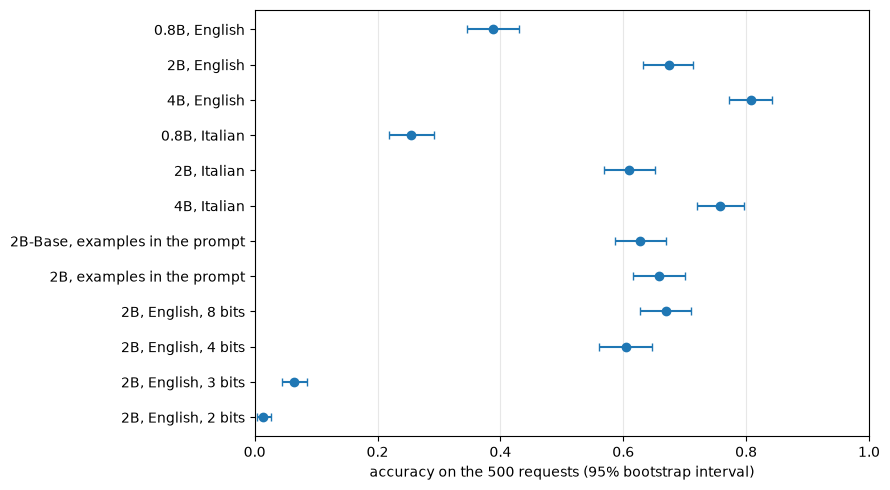

run,accuracy,low,high,seconds
"0.8B, English",0.388,0.346,0.430,65
"2B, English",0.674,0.632,0.714,125
"4B, English",0.808,0.772,0.842,299
"0.8B, Italian",0.254,0.218,0.292,65
"2B, Italian",0.610,0.568,0.652,120
"4B, Italian",0.758,0.720,0.796,299
"2B-Base, examples in the prompt",0.628,0.586,0.670,176
"2B, examples in the prompt",0.658,0.616,0.700,183
"2B, English, 8 bits",0.670,0.628,0.710,120
"2B, English, 4 bits",0.604,0.560,0.646,128


In [42]:
def correct(result, gold=GOLD):
    # 1 for each request answered with the right intent, 0 otherwise
    return np.array([read_intent(a) == g for a, g in zip(result["answers"], gold)], dtype=float)

def bootstrap(values, n=10_000, seed=0):
    # the mean and a 95% interval: the 2.5 and 97.5 percentiles of the means of n samples of the same size drawn with replacement
    rng = np.random.default_rng(seed)
    means = values[rng.integers(0, len(values), (n, len(values)))].mean(axis=1)
    return values.mean(), *np.percentile(means, [2.5, 97.5])

rows = []
for label, result in RESULTS.items():
    mean, low, high = bootstrap(correct(result))
    rows.append({"run": label, "accuracy": mean, "low": low, "high": high, "seconds": result["seconds"]})
accuracy = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(accuracy["accuracy"], range(len(accuracy)), xerr=[accuracy["accuracy"] - accuracy["low"], accuracy["high"] - accuracy["accuracy"]], fmt="o", capsize=3)
ax.set_yticks(range(len(accuracy)), accuracy["run"]); ax.invert_yaxis()
ax.set_xlabel("accuracy on the 500 requests (95% bootstrap interval)"); ax.set_xlim(0, 1); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()
accuracy.style.format({"accuracy": "{:.3f}", "low": "{:.3f}", "high": "{:.3f}", "seconds": "{:.0f}"}).hide(axis="index")

The size counts more than anything else here: 0.388 for the 0.8B, 0.674 for the 2B, 0.808 for the 4B, with intervals of about ±4 points that do not overlap. In Italian every size loses: 0.254, 0.610 and 0.758. The base model with the examples in the prompt gets 0.628, close to the instruct model with the same prompt (0.658) and to the instruct model in the chat template (0.674). Rounding to 8 bits changes nothing (0.670); 4 bits cost something (0.604); 3 and 2 bits destroy the model (0.064 and 0.014), as they destroyed its perplexity in Step 4. The 2B needs a quarter of a second per request (125 seconds for 500), the 4B 2.4 times as much.

**Comparing on the same requests.** Two intervals that overlap do not mean that two models are equivalent: the two models answered the *same* requests, and many requests are easy (or hard) for both. The right comparison is **paired**: for each resampled set of requests we compute the difference between the two accuracies on that same set, and look at the interval of the differences. We also count the requests on which only one of the two is right: the difference depends only on these.

In [43]:
def paired(a, b, n=10_000, seed=0):
    # the difference of accuracy a - b on the same requests, with a 95% interval computed on the same resampled requests for both
    ca, cb = correct(RESULTS[a]), correct(RESULTS[b])
    index = np.random.default_rng(seed).integers(0, len(ca), (n, len(ca)))
    low, high = np.percentile(ca[index].mean(axis=1) - cb[index].mean(axis=1), [2.5, 97.5])
    return {"first": a, "second": b, "difference": ca.mean() - cb.mean(), "low": low, "high": high,
            "only the first is right": int(((ca == 1) & (cb == 0)).sum()), "only the second": int(((ca == 0) & (cb == 1)).sum())}

COMPARISONS = [("2B, English", "0.8B, English"), ("4B, English", "2B, English"),
               ("0.8B, English", "0.8B, Italian"), ("2B, English", "2B, Italian"), ("4B, English", "4B, Italian"),
               ("2B, examples in the prompt", "2B-Base, examples in the prompt"), ("2B, examples in the prompt", "2B, English"),
               ("2B, English", "2B, English, 8 bits"), ("2B, English", "2B, English, 4 bits"), ("2B, English", "2B, English, 3 bits")]
pd.DataFrame([paired(a, b) for a, b in COMPARISONS]).style.format({"difference": "{:+.3f}", "low": "{:+.3f}", "high": "{:+.3f}"}).hide(axis="index")

first,second,difference,low,high,only the first is right,only the second
"2B, English","0.8B, English",+0.286,+0.242,+0.330,153,10
"4B, English","2B, English",+0.134,+0.096,+0.172,85,18
"0.8B, English","0.8B, Italian",+0.134,+0.094,+0.174,88,21
"2B, English","2B, Italian",+0.064,+0.024,+0.102,67,35
"4B, English","4B, Italian",+0.050,+0.022,+0.078,39,14
"2B, examples in the prompt","2B-Base, examples in the prompt",+0.030,-0.002,+0.062,41,26
"2B, examples in the prompt","2B, English",-0.016,-0.058,+0.026,56,64
"2B, English","2B, English, 8 bits",+0.004,-0.008,+0.016,6,4
"2B, English","2B, English, 4 bits",+0.070,+0.036,+0.104,58,23
"2B, English","2B, English, 3 bits",+0.610,+0.566,+0.654,310,5


The paired intervals confirm what the table suggests, and say more. The 2B is better than the 0.8B by 28.6 points (from 24.2 to 33.0): it is right on 153 requests where the 0.8B is wrong, and wrong on only 10 where the 0.8B is right. The 4B adds 13.4 points (from 9.6 to 17.2). Italian costs 13.4 points to the 0.8B, 6.4 to the 2B and 5.0 to the 4B, all with intervals above zero: the larger the model, the smaller the gap between the two languages. Three differences are **not** supported by our data: the instruct model beats the base model with the same prompt by 3.0 points, but the interval goes from −0.2 to +6.2; the examples in the prompt do not help the instruct model (−1.6, from −5.8 to +2.6); and 8 bits are the same as 16 (+0.4, from −0.8 to +1.6: 6 requests against 4). Four bits with our simple rounding cost 7.0 points (from 3.6 to 10.4), a loss that the 10% of perplexity of Step 4 did not make look important. All of this holds for this task, these prompts and these 500 requests; to say that two settings are equivalent with more confidence, we would need more requests.

**Thinking.** Does the 2B classify better if it reasons first? Thinking is expensive, so we try it on the first 32 requests only, with the settings that the card recommends for thinking, and with at most 2,048 tokens for each answer; the answer is read after `</think>`.

In [44]:
def thinking_run():
    torch.manual_seed(0)
    return write(model, tokenizer, [chat_prompt(tokenizer, t, thinking=True) for t in TEXTS[:32]], max_new_tokens=2048, batch_size=16, **SAMPLING[True])

thought = cached("en-2B-thinking-32", thinking_run)
finished = ["</think>" in a for a in thought["answers"]]
think_tokens = [len(tokenizer(a.split("</think>")[0]).input_ids) for a, f in zip(thought["answers"], finished) if f]
with_thinking = [read_intent(a.split("</think>")[-1], tolerant=True) if f else None for a, f in zip(thought["answers"], finished)]
without = RESULTS["2B, English"]
right_off = [read_intent(a) == g for a, g in zip(without["answers"][:32], GOLD[:32])]
right_on = [p == g for p, g in zip(with_thinking, GOLD[:32])]
pd.DataFrame({"thinking off (the run above)": {"accuracy on the 32 requests": np.mean(right_off), "answers finished within the limit": 1.0,
                                               "accuracy on the answers that finished with thinking": np.mean([r for r, f in zip(right_off, finished) if f]),
                                               "tokens per answer": without["tokens"] / len(TEXTS), "seconds per request": without["seconds"] / len(TEXTS)},
              "thinking on": {"accuracy on the 32 requests": np.mean(right_on), "answers finished within the limit": np.mean(finished),
                              "accuracy on the answers that finished with thinking": np.mean([r for r, f in zip(right_on, finished) if f]),
                              "tokens per answer": thought["tokens"] / 32, "seconds per request": thought["seconds"] / 32}}).style.format("{:.2f}")

en-2B-thinking-32: loaded from the cache


,thinking off (the run above),thinking on
accuracy on the 32 requests,0.69,0.50
answers finished within the limit,1.00,0.59
accuracy on the answers that finished with thinking,0.79,0.84
tokens per answer,7.55,1306.06
seconds per request,0.25,10.57


With thinking the 2B writes 1,306 tokens per answer instead of 7.6, and takes 10.6 seconds per request instead of 0.25: 42 times as long. Only 19 of the 32 reasonings (59%) finished within 2,048 tokens; the others count as wrong, and the accuracy on the 32 requests falls from 0.69 to 0.50. The unfinished reasonings hesitate between close intents and go back to the list again and again (`Wait, looking at the list again ...`). On the 19 requests where the reasoning finished, the model is right 16 times with thinking and 15 times without (0.84 and 0.79): no visible gain, at a very high cost. Thinking helps problems that need steps (the card reports 11 points more on MMLU-Pro), not necessarily a classification; and 32 requests are enough to see the cost, not to measure a gain.

**Perplexity is not accuracy.** The perplexity (L0.7) is often used to compare models, and in Step 4 it told us how much the rounding damaged the model. Two warnings. It is a measure *per token*, so it can be compared only between models with the same tokenizer: a tokenizer with longer tokens has fewer tokens, each harder to guess, and a higher perplexity for the same text. The measure that can be compared across tokenizers is the number of **bits per byte** of text, the same negative log-likelihood divided by the bytes instead of the tokens. And a better perplexity on a text does not say how a model does a task. We measure both on the same 100,000 characters of WikiText-2 for the three sizes and for GPT-2 (L1.4), and we put them next to the accuracy on our task.

In [45]:
def text_quality(name):
    def compute():
        t = AutoTokenizer.from_pretrained(name)
        m = AutoModelForCausalLM.from_pretrained(name, device_map=DEVICE).eval()
        result = read_text(m, t, TEXT)[0]
        del m
        release()
        return result
    return compute

reading = {"GPT-2 (124M, L1.4)": cached("wikitext-gpt2", text_quality("gpt2")),
           "Qwen3.5-0.8B": cached("wikitext-0.8B", text_quality(SMALL)),
           "Qwen3.5-2B": quality["16 bits (bfloat16)"],                                    # measured in Step 4
           "Qwen3.5-4B": cached("wikitext-4B", text_quality(LARGE))}
table = pd.DataFrame(reading).T
table["accuracy on our task"] = [float("nan")] + [correct(RESULTS[f"{size}, English"]).mean() for size in ("0.8B", "2B", "4B")]
levels = {"16 bits (bfloat16)": "2B, English", **{f"{b} bits, groups of 64": f"2B, English, {b} bits" for b in (8, 4, 3, 2)}}
bits_table = pd.DataFrame({"perplexity": [quality[k]["perplexity"] for k in levels], "bits per byte": [quality[k]["bits per byte"] for k in levels],
                           "accuracy on our task": [correct(RESULTS[v]).mean() for v in levels.values()]}, index=[f"Qwen3.5-2B, {k}" for k in levels])
pd.concat([table, bits_table]).style.format({"tokens": "{:,.0f}", "perplexity": "{:.2f}", "bits per byte": "{:.3f}", "accuracy on our task": "{:.3f}"}, na_rep="")

wikitext-gpt2: loaded from the cache
wikitext-0.8B: loaded from the cache
wikitext-4B: loaded from the cache


,tokens,perplexity,bits per byte,accuracy on our task
"GPT-2 (124M, L1.4)","22,604",31.13,1.119,
Qwen3.5-0.8B,"24,490",18.50,1.028,0.388
Qwen3.5-2B,"24,490",12.36,0.886,0.674
Qwen3.5-4B,"24,490",9.65,0.799,0.808
"Qwen3.5-2B, 16 bits (bfloat16)",,12.36,0.886,0.674
"Qwen3.5-2B, 8 bits, groups of 64",,12.36,0.886,0.670
"Qwen3.5-2B, 4 bits, groups of 64",,13.64,0.921,0.604
"Qwen3.5-2B, 3 bits, groups of 64",,65.41,1.474,0.064
"Qwen3.5-2B, 2 bits, groups of 64",,1927767.83,5.101,0.014


Among the three Qwen3.5 sizes, which share the tokenizer, the perplexity goes down with the size (18.50, 12.36, 9.65) while the accuracy goes up (0.388, 0.674, 0.808): here the two agree. GPT-2 shows why perplexities of different tokenizers cannot be compared: its tokenizer, made for English, cuts the same text into fewer tokens (22,604 against 24,490), and per token its perplexity is 31.13, 1.7 times that of the 0.8B, while per byte the difference is 9% (1.119 bits against 1.028). Across the bits, perplexity and accuracy move together too, but not in proportion: 4 bits add 10% to the perplexity and take 7 points of accuracy; 3 bits multiply the perplexity by five and leave a tenth of the accuracy. A perplexity tells us that something changed; how much it matters, only a measure on the task can tell.

## What changes in production, and the limits of this notebook

**What this notebook did not show.**

* **The scale.** Models from 0.8 to 4 billion parameters, on a laptop. Larger models do better at most tasks (Step 8 shows how much the size counts even between 0.8B and 4B); the methods of the notebook do not change.
* **One task, one prompt.** Intent classification, 500 requests, two languages, one prompt (two in Step 6). We did not search for a better prompt or for better examples, and we do not know how the differences we measured carry over to other tasks.
* **The library.** `transformers` is not a serving engine: the times of Step 7 are those of static batches on a Mac, with the reference implementation of the linear-attention layers. An engine on a GPU is much faster, and we did not run one (Appendix A).
* **Quantization by simulation.** Our rounding (Step 4) is the simplest one, round-to-nearest, and it saved no memory; GGUF, MLX, GPTQ and AWQ do better with the same number of bits, and are faster.
* **Thinking** was measured on 32 requests with one setting: an illustration, not a measure.
* **Contamination.** MASSIVE has been public since 2022: we do not know whether these models have seen it.


## Conclusions

What we saw (one machine, the models and the data of the notebook):

1. **Most of what we need to know to choose a model is written before we run it.** The name, the card and the configuration give the size, the training (base, instruct, thinking), the architecture (a mixture of experts uses 1 billion of the 32 billion parameters of its experts for each token; only 6 of the 24 layers of Qwen3.5-2B have full attention) and the licence. The tokenizer gives the price of a language: the same requests cost 1.21 times the tokens of English in Italian with Qwen3.5, and up to 7.8 times in Amharic with SmolLM3.
2. **Memory is arithmetic.** The weights are parameters times bytes (1.88 billion × 2 = 3.76 GB, as measured); training with Adam needs 16 bytes per parameter before the activations; the cache grows by $2 \times \text{layers} \times \text{key-value heads} \times \text{head size} \times \text{bytes}$ per token, 12 KiB for Qwen3.5-2B against 112 KiB for Qwen3-1.7B, exactly as measured.
3. **Fewer bits cost little until they cost everything, and the groups decide how much.** One scale for a whole matrix sends 89% of its weights to 0 at 4 bits, groups of 64 keep the error at 11%. On the whole model 8 bits change nothing (accuracy 0.670 against 0.674), 4 bits of simple rounding cost 7 points, 3 bits destroy it.
4. **The chat template is part of the model.** It differs between families and between sizes of the same family (the 4B thinks by default, the 2B does not), it can add text of its own (a date, a level of reasoning), and the answer must be decoded from the new tokens only. The base model of 2026 answers in the chat template like the instruct one, and with examples in the prompt it is within 3 points of it on our task, a difference that our 500 requests cannot confirm.
5. **A prompt asks for a format, constrained decoding guarantees it.** Free answers were unreadable in up to 35% of the cases and contained invented intents; with the constraint all of them were valid, the 0.8B with the casual prompt went from 0.260 to 0.414 with answers four times shorter, and the 2B with the strict prompt stayed at 0.674: valid is not right. Tools are structured answers that our program executes: the 2B chose the right tool in 67% of the cases and called a tool that was not needed in 22.5%.
6. **Writing is limited by the memory, reading by the computation.** The 2B writes 55 tokens per second, reading its 3.76 GB of weights for each one, and reads prompts at about 1,500 tokens per second. Batches make the writing cheaper, so with our short answers and long prompts they gained only 1.7 times; and they change the answers: 7 of 128 greedy answers changed with the size of the batch.
7. **Measure on your task, with intervals and on the same requests.** The sizes differ by 29 and 13 points, Italian costs 5 to 13 points, 4 bits cost 7; base and instruct with examples, examples and no examples, 8 and 16 bits cannot be told apart on 500 requests. Thinking took 42 times as long without a visible gain on this task. The perplexity agreed with the accuracy in direction, not in size, and can be compared only between models with the same tokenizer.

## Appendix A: the same requests with an inference engine

`transformers` is the library to load, study and change models; to *serve* many requests we use an **inference engine**, with continuous batching, paged caches, prefix caching and its own kernels (Step 7). The engines differ in where they run, but they share one thing: a server that speaks the **OpenAI-compatible** API (`POST /v1/chat/completions`, with the messages of Step 5), so the code of the client is the same for all of them, and for most paid APIs (Appendix B). Only the address changes.

| engine | where it runs | format of the model | notes |
|---|---|---|---|
| `transformers serve` | wherever `transformers` runs | Hub (safetensors) | quick tests; `--continuous-batching` |
| llama.cpp (`llama-server`) | CPU, Apple silicon, NVIDIA and AMD GPUs | GGUF | one file per model; its library (GGML) is also under Ollama and LM Studio |
| MLX LM (`mlx_lm.server`) | Apple silicon only | MLX | made for the Mac; not meant for production |
| vLLM | Linux with a GPU | Hub (16 bits, FP8, GPTQ, AWQ) | PagedAttention; widely used to serve open models at scale |
| SGLang | Linux with a GPU | Hub | close to vLLM, with a cache of prefixes shared among requests |

The cells below use the variables of the notebook (`SYSTEM`, `TEXTS`, `GOLD`, `Answer`, `INTENT_SCHEMA`, `read_intent`). The commands that start a server go in a terminal, not in the notebook: a server never ends.

**A.1 The client**, the same for every engine.

In [ ]:
# pip install openai
from openai import OpenAI

def classify(client, model, text, schema=INTENT_SCHEMA):
    # one request to an OpenAI-compatible server; with a schema the server constrains the answer, as in Step 6
    options = {"response_format": {"type": "json_schema", "json_schema": {"name": "intent", "schema": schema}}} if schema else {}
    response = client.chat.completions.create(model=model, max_tokens=32, temperature=0,
                                              messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": text}], **options)
    return response.choices[0].message.content, response.usage

**A.2 llama.cpp.** Installation and server, in a terminal:

```bash
brew install llama.cpp       # macOS; for Linux and Windows, the binaries in github.com/ggml-org/llama.cpp/releases
llama-server -hf unsloth/Qwen3.5-2B-GGUF:Q4_K_M --port 8080 -c 16384 -np 4 --chat-template-kwargs '{"enable_thinking": false}'
```

`-hf` downloads the GGUF file from the Hub (the quantization after the `:`, Step 4); `-c` is the context in tokens, shared by the `-np` requests served in parallel; the chat template is the one inside the GGUF file, with its settings in `--chat-template-kwargs`.

In [ ]:
server = OpenAI(base_url="http://localhost:8080/v1", api_key="none")      # llama-server checks no key, unless started with --api-key
answers = [classify(server, "qwen3.5-2b", text)[0] for text in TEXTS[:50]]
print(answers[:3], np.mean([read_intent(a) == g for a, g in zip(answers, GOLD)]))

# the same engine inside Python, without a server: pip install llama-cpp-python (on a Mac it uses Metal)
from llama_cpp import Llama

llm = Llama.from_pretrained(repo_id="unsloth/Qwen3.5-2B-GGUF", filename="Qwen3.5-2B-Q4_K_M.gguf", n_ctx=8192, n_gpu_layers=-1, verbose=False)
out = llm.create_chat_completion(messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": TEXTS[0]}], temperature=0, max_tokens=32,
                                 response_format={"type": "json_object", "schema": INTENT_SCHEMA})      # the format of this library, not of the OpenAI API
print(out["choices"][0]["message"]["content"], out["usage"])

**A.3 MLX LM** (Apple silicon only). In Python, without a server:

In [ ]:
# pip install mlx-lm
from mlx_lm import load, generate
from mlx_lm.sample_utils import make_sampler

mlx_model, mlx_tokenizer = load("mlx-community/Qwen3.5-2B-4bit")        # 4 bits, groups of 64 (Step 4); MLX LM ignores the vision encoder
prompt = mlx_tokenizer.apply_chat_template([{"role": "system", "content": SYSTEM}, {"role": "user", "content": TEXTS[0]}],
                                           add_generation_prompt=True, enable_thinking=False)
print(generate(mlx_model, mlx_tokenizer, prompt=prompt, max_tokens=32, sampler=make_sampler(temp=0.0), verbose=True))   # verbose: speed and memory

As a server, in a terminal (`mlx_lm.server` does not constrain the answers: no `response_format`), and to make a 4-bit copy of a model yourself:

```bash
mlx_lm.server --model mlx-community/Qwen3.5-2B-4bit --port 8081
mlx_lm.convert --model Qwen/Qwen3.5-2B -q        # quantized (by default 4 bits, groups of 64) into the folder mlx_model
```

In [ ]:
mlx_server = OpenAI(base_url="http://localhost:8081/v1", api_key="none")
print(classify(mlx_server, "mlx-community/Qwen3.5-2B-4bit", TEXTS[0], schema=None))

**A.4 vLLM** (Linux with an NVIDIA GPU, for example a GPU of Colab; it does not run on macOS). In Python, the engine receives all the requests at once and schedules them itself:

In [ ]:
# pip install vllm
from vllm import LLM, SamplingParams
from vllm.sampling_params import StructuredOutputsParams

llm = LLM(model="Qwen/Qwen3.5-2B", max_model_len=8192)                  # on a GPU without bfloat16 (the T4 of Colab) add dtype="half"
conversations = [[{"role": "system", "content": SYSTEM}, {"role": "user", "content": text}] for text in TEXTS]
params = SamplingParams(temperature=0, max_tokens=32, structured_outputs=StructuredOutputsParams(json=INTENT_SCHEMA))
start = time.time()
outputs = llm.chat(conversations, params, chat_template_kwargs={"enable_thinking": False})
print(f"{len(outputs)} answers in {time.time() - start:.1f} s; accuracy {np.mean([read_intent(o.outputs[0].text) == g for o, g in zip(outputs, GOLD)]):.3f}")

As a server (then the client of A.1 with `base_url="http://localhost:8000/v1"`), and with the batch-invariant kernels of Step 7:

```bash
vllm serve Qwen/Qwen3.5-2B --port 8000 --max-model-len 8192 --language-model-only     # without the vision encoder: more memory for the cache
VLLM_BATCH_INVARIANT=1 vllm serve Qwen/Qwen3.5-2B --port 8000 --max-model-len 8192
```

**A.5 Others.** All of them serve the same API:

```bash
pip install "transformers[serving]"; transformers serve --force-model Qwen/Qwen3.5-2B --port 8000 --continuous-batching
ollama run qwen3.5:2b                       # Ollama (GGUF): the API at http://localhost:11434/v1
python -m sglang.launch_server --model-path Qwen/Qwen3.5-2B --port 8000      # SGLang (Linux with a GPU)
```

LM Studio is a desktop application (GGUF and MLX models) with a local server at `http://localhost:1234/v1`.

## Appendix B: a paid API

A paid API runs a model, closed or open, on the servers of a company: no hardware to manage, the largest models, and a cost for every token. Before using one:

* **The key.** An API key is a password that spends money. Never write it in a notebook or in a repository: keys published by mistake are found by programs that scan public repositories. Put it in an environment variable (`export OPENAI_API_KEY=...` in the terminal, or a `.env` file that git ignores, read with `python-dotenv`): the SDKs read it from there.
* **The cost** is per million tokens, different for the input and the output (the tokens of the thinking are output, Step 5), with a discount for the input tokens of a prefix seen in a recent request (Step 7) and a discount of 50% for *batch* jobs, which return within a day. The tokens depend on the tokenizer and on the language (Step 2).
* **The models change**: names are updated and old models retired.
* **Reproducibility** is not guaranteed (Step 7), and some recent models do not accept a temperature.
* **The data** leave your machine. Read the terms on how long they are kept and whether they are used for training, and do not send personal data without a legal basis (GDPR).

**B.1 OpenAI.** The client of Appendix A without `base_url`; the pydantic class of Step 6 as the format of the answer.

In [ ]:
# pip install openai; in the terminal: export OPENAI_API_KEY=...
from openai import OpenAI

openai_client = OpenAI()                          # the address of OpenAI and the key from the environment
MODEL = "gpt-6-luna"                              # the cheapest text model listed on 16 November 2026: developers.openai.com/api/docs/models

completion = openai_client.chat.completions.parse(model=MODEL, response_format=Answer,       # the answer is constrained to the schema of Answer
                                                  messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": TEXTS[0]}])
message = completion.choices[0].message
print(message.parsed if message.parsed else message.refusal, completion.usage)

# the same with the Responses API
response = openai_client.responses.parse(model=MODEL, instructions=SYSTEM, input=TEXTS[0], text_format=Answer)
print(response.output_parsed, response.usage)

# what a request costs: the prices change, see developers.openai.com/api/docs/pricing
PRICE = {"input": 0.10, "cached input": 0.01, "output": 0.50}          # dollars per million tokens, gpt-6-luna, 16 November 2026
usage = completion.usage
cached_tokens = usage.prompt_tokens_details.cached_tokens if usage.prompt_tokens_details else 0
cost = ((usage.prompt_tokens - cached_tokens) * PRICE["input"] + cached_tokens * PRICE["cached input"] + usage.completion_tokens * PRICE["output"]) / 1e6
print(f"{usage.prompt_tokens} tokens in ({cached_tokens} cached), {usage.completion_tokens} out: ${cost:.6f}; the 2,974 requests of the test set: about ${2974 * cost:.2f}")

**B.2 Anthropic.** Not every provider uses the OpenAI format: the Messages API of Anthropic has its own SDK, the system prompt is a field of the request and not a message, and the format of the answer goes in `output_config`. Its current models think before answering and do not accept a temperature; `effort` sets how much they think. The request below also asks that, if the safety classifiers decline it, it is retried on another model (`fallbacks`).

In [ ]:
# pip install anthropic; in the terminal: export ANTHROPIC_API_KEY=...
import anthropic

claude = anthropic.Anthropic()                    # the key from the environment
response = claude.beta.messages.create(
    model="claude-opus-5-5",                      # models and prices: platform.claude.com/docs/en/about-claude/models/overview
    max_tokens=4096,                              # the thinking counts in max_tokens
    system=SYSTEM,
    messages=[{"role": "user", "content": TEXTS[0]}],
    output_config={"effort": "low",               # little thinking: a classification does not need more
                   "format": {"type": "json_schema", "schema": INTENT_SCHEMA}},
    betas=["server-side-fallback-2026-07-01"],
    fallbacks="default",
)
if response.stop_reason == "refusal":
    print("declined:", response.stop_details)
else:
    print(next(block.text for block in response.content if block.type == "text"), response.usage)

**B.3 Other providers.** Many speak the OpenAI-compatible API: the client of Appendix A with their address and their key, for example Google (`base_url="https://generativelanguage.googleapis.com/v1beta/openai/"`) or the Inference Providers of Hugging Face, which serve open models of the Hub (`base_url="https://router.huggingface.co/v1"`, with a token of the Hub as the key). Check in the documentation of each provider the names of the models and which options (`response_format`, tools, temperature) are supported.

## Appendix C: fine-tuning with the libraries

In L1.5 and L1.6 we fine-tuned our networks with a few lines of PyTorch. With real models the same steps are done by libraries: `Trainer` of `transformers`, `peft` for LoRA, `trl` for instruction and preference tuning, `mlx-lm` on a Mac. When is it worth it? When the prompt is not enough and there are labeled examples: our best result without training is 0.808 (the 4B, in English), and MASSIVE has 11,514 labeled requests in English (and as many in each language). Three ways, from the simplest.

**C.1 An encoder with a classification head** (L1.3, *a head for every task*). For a classification with many examples a small encoder is often enough, and it is fast: XLM-RoBERTa (Conneau et al., 2020) was trained on 100 languages, so we can train it in English and test it in Italian.

In [ ]:
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer, TrainingArguments

ENCODER = "FacebookAI/xlm-roberta-base"
label2id = {label: i for i, label in enumerate(LABELS)}
encoder_tokenizer = AutoTokenizer.from_pretrained(ENCODER)

def encode(batch):
    return {**encoder_tokenizer(batch["text"], truncation=True, max_length=64), "labels": [label2id[label] for label in batch["label"]]}

data = massive.map(encode, batched=True, remove_columns=massive["train"].column_names)
italian = load_dataset("mteb/amazon_massive_intent", "it", split="test")
italian = italian.map(encode, batched=True, remove_columns=italian.column_names)
classifier = AutoModelForSequenceClassification.from_pretrained(ENCODER, num_labels=len(LABELS), id2label=dict(enumerate(LABELS)), label2id=label2id)

def accuracy_of(prediction):
    return {"accuracy": (prediction.predictions.argmax(-1) == prediction.label_ids).mean()}

trainer = Trainer(model=classifier, train_dataset=data["train"], eval_dataset=data["validation"], compute_metrics=accuracy_of,
                  data_collator=DataCollatorWithPadding(encoder_tokenizer),
                  args=TrainingArguments(output_dir=f"{CACHE}/xlm-r-massive", num_train_epochs=3, per_device_train_batch_size=32,
                                         learning_rate=3e-5, eval_strategy="epoch", save_strategy="no", report_to="none"))
trainer.train()
print("English test:", trainer.evaluate(data["test"]))
print("Italian test (no Italian in the training):", trainer.evaluate(italian))

**C.2 LoRA on the decoder** (L1.5 and L1.6, Step 3) with `trl` and `peft`, on an NVIDIA GPU. The examples are *prompt* and *completion*: the loss is computed only on the completion, as in L1.5 only on the words after `<sep>`. After the training the list of the 60 intents is no longer needed in the prompt (the model has learned them), and each request costs about 270 tokens less (Step 6).

In [ ]:
# pip install trl peft
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer

SHORT = "Classify the request of the user into one intent."

def as_example(row):
    return {"prompt": [{"role": "system", "content": SHORT}, {"role": "user", "content": row["text"]}],
            "completion": [{"role": "assistant", "content": json.dumps({"intent": row["label"]})}]}

train = massive["train"].map(as_example, remove_columns=massive["train"].column_names)
trainer = SFTTrainer(model="Qwen/Qwen3.5-0.8B", train_dataset=train,
                     peft_config=LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM"),
                     args=SFTConfig(output_dir=f"{CACHE}/qwen3.5-0.8B-lora-massive", num_train_epochs=1, per_device_train_batch_size=16,
                                    learning_rate=2e-4, report_to="none"))
trainer.train()
trainer.save_model()                              # only the adapter is saved (L1.5, Step 5)

# QLoRA: the same, with the frozen weights loaded in 4 bits (NF4, Step 4); bitsandbytes needs an NVIDIA GPU
from transformers import BitsAndBytesConfig
qlora_args = SFTConfig(output_dir=f"{CACHE}/qwen3.5-0.8B-qlora-massive", num_train_epochs=1, per_device_train_batch_size=16, learning_rate=2e-4,
                       report_to="none", model_init_kwargs={"quantization_config": BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                                                                      bnb_4bit_compute_dtype=torch.bfloat16)})

**C.3 LoRA with MLX** (Apple silicon). MLX LM wants a folder with `train.jsonl` and `valid.jsonl`, one conversation per line:

In [ ]:
os.makedirs("massive-mlx", exist_ok=True)
for split, file in (("train", "train.jsonl"), ("validation", "valid.jsonl")):
    with open(f"massive-mlx/{file}", "w") as f:
        for row in massive[split]:
            f.write(json.dumps({"messages": [{"role": "system", "content": "Classify the request of the user into one intent."},
                                             {"role": "user", "content": row["text"]},
                                             {"role": "assistant", "content": json.dumps({"intent": row["label"]})}]}) + "\n")

Then, in a terminal (a 4-bit model as a base: MLX LM does QLoRA by itself):

```bash
pip install "mlx-lm[train]"
mlx_lm.lora --model mlx-community/Qwen3.5-0.8B-4bit --train --data massive-mlx --iters 600     # the adapter goes in adapters/
mlx_lm.fuse --model mlx-community/Qwen3.5-0.8B-4bit                                           # the adapter merged into the weights
```

**C.4 Beyond.** Preference tuning (L1.6, Steps 4-6) is in `trl` too (`DPOTrainer`, with pairs of chosen and rejected answers). Unsloth makes LoRA and QLoRA faster and lighter on a single NVIDIA GPU, and publishes notebooks that run on Colab. Before choosing, compute the memory as in Step 3: the full fine-tuning of a 2B needs about 32 GB plus the activations, LoRA a little more than the weights.

### References

* Ainslie, J., Lee-Thorp, J., de Jong, M., et al. (2023). *GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints.* EMNLP 2023.
* Attanasio, G., Basile, P., Borazio, F., et al. (2024). *CALAMITA: Challenge the Abilities of LAnguage Models in ITAlian.* CLiC-it 2024.
* Bastianelli, E., Vanzo, A., Swietojanski, P., Rieser, V. (2020). *SLURP: A Spoken Language Understanding Resource Package.* EMNLP 2020.
* Chiang, W.-L., Zheng, L., Sheng, Y., et al. (2024). *Chatbot Arena: An Open Platform for Evaluating LLMs by Human Preference.* ICML 2024.
* Conneau, A., Khandelwal, K., Goyal, N., et al. (2020). *Unsupervised Cross-lingual Representation Learning at Scale.* ACL 2020.
* Dao, T., Fu, D. Y., Ermon, S., Rudra, A., Ré, C. (2022). *FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness.* NeurIPS 2022.
* Dao, T. (2023). *FlashAttention-2: Faster Attention with Better Parallelism and Work Partitioning.* arXiv:2307.08691.
* Dettmers, T., Pagnoni, A., Holtzman, A., Zettlemoyer, L. (2023). *QLoRA: Efficient Finetuning of Quantized LLMs.* NeurIPS 2023.
* Dong, Y., Ruan, C. F., Cai, Y., et al. (2024). *XGrammar: Flexible and Efficient Structured Generation Engine for Large Language Models.* arXiv:2411.15100.
* Efron, B., Tibshirani, R. J. (1993). *An Introduction to the Bootstrap.* Chapman & Hall.
* FitzGerald, J., Hench, C., Peris, C., et al. (2023). *MASSIVE: A 1M-Example Multilingual Natural Language Understanding Dataset with 51 Typologically-Diverse Languages.* ACL 2023.
* Frantar, E., Ashkboos, S., Hoefler, T., Alistarh, D. (2023). *GPTQ: Accurate Post-Training Quantization for Generative Pre-trained Transformers.* ICLR 2023.
* Gema, A. P., Leang, J. O. J., Hong, G., et al. (2025). *Are We Done with MMLU?* NAACL 2025.
* Greshake, K., Abdelnabi, S., Mishra, S., et al. (2023). *Not What You've Signed Up For: Compromising Real-World LLM-Integrated Applications with Indirect Prompt Injection.* AISec 2023.
* He, H. (2025). *Defeating Nondeterminism in LLM Inference.* Thinking Machines Lab, Connectionism (blog), September 2025.
* Hendrycks, D., Burns, C., Basart, S., et al. (2021). *Measuring Massive Multitask Language Understanding.* ICLR 2021.
* Hsieh, C.-P., Sun, S., Kriman, S., et al. (2024). *RULER: What's the Real Context Size of Your Long-Context Language Models?* COLM 2024.
* Jain, N., Han, K., Gu, A., et al. (2024). *LiveCodeBench: Holistic and Contamination Free Evaluation of Large Language Models for Code.* arXiv:2403.07974.
* Jimenez, C. E., Yang, J., Wettig, A., et al. (2024). *SWE-bench: Can Language Models Resolve Real-World GitHub Issues?* ICLR 2024.
* Keskar, N. S., McCann, B., Varshney, L. R., Xiong, C., Socher, R. (2019). *CTRL: A Conditional Transformer Language Model for Controllable Generation.* arXiv:1909.05858.
* Kwon, W., Li, Z., Zhuang, S., et al. (2023). *Efficient Memory Management for Large Language Model Serving with PagedAttention.* SOSP 2023.
* Leviathan, Y., Kalman, M., Matias, Y. (2023). *Fast Inference from Transformers via Speculative Decoding.* ICML 2023.
* Lin, J., Tang, J., Tang, H., et al. (2024). *AWQ: Activation-aware Weight Quantization for On-Device LLM Compression and Acceleration.* MLSys 2024.
* Liu, N. F., Lin, K., Hewitt, J., et al. (2024). *Lost in the Middle: How Language Models Use Long Contexts.* TACL 12.
* Merity, S., Xiong, C., Bradbury, J., Socher, R. (2017). *Pointer Sentinel Mixture Models.* ICLR 2017.
* Muennighoff, N., Tazi, N., Magne, L., Reimers, N. (2023). *MTEB: Massive Text Embedding Benchmark.* EACL 2023.
* Nguyen, M. N., Baker, A., Neo, C., et al. (2025). *Turning Up the Heat: Min-p Sampling for Creative and Coherent LLM Outputs.* ICLR 2025.
* Phan, L., Gatti, A., Han, Z., et al. (2025). *Humanity's Last Exam.* arXiv:2501.14249.
* Qwen Team (2026). *Qwen3.5: Towards Native Multimodal Agents.* Model cards on the Hugging Face Hub, February 2026.
* Rajbhandari, S., Rasley, J., Ruwase, O., He, Y. (2020). *ZeRO: Memory Optimizations Toward Training Trillion Parameter Models.* SC 2020.
* Rein, D., Hou, B. L., Stickland, A. C., et al. (2024). *GPQA: A Graduate-Level Google-Proof Q&A Benchmark.* COLM 2024.
* Sainz, O., Campos, J. A., García-Ferrero, I., et al. (2023). *NLP Evaluation in Trouble: On the Need to Measure LLM Data Contamination for each Benchmark.* Findings of EMNLP 2023.
* Singh, S., Nan, Y., Wang, A., et al. (2025). *The Leaderboard Illusion.* arXiv:2504.20879.
* Tam, Z. R., Wu, C.-K., Tsai, Y.-L., et al. (2024). *Let Me Speak Freely? A Study on the Impact of Format Restrictions on Performance of Large Language Models.* EMNLP 2024 (Industry Track).
* Wang, Y., Ma, X., Zhang, G., et al. (2024). *MMLU-Pro: A More Robust and Challenging Multi-Task Language Understanding Benchmark.* NeurIPS 2024 (Datasets and Benchmarks).
* Willard, B. T., Louf, R. (2023). *Efficient Guided Generation for Large Language Models.* arXiv:2307.09702.
* Yang, S., Kautz, J., Hatamizadeh, A. (2025). *Gated Delta Networks: Improving Mamba2 with Delta Rule.* ICLR 2025.
* Yu, G.-I., Jeong, J. S., Kim, G.-W., Kim, S., Chun, B.-G. (2022). *Orca: A Distributed Serving System for Transformer-Based Generative Models.* OSDI 2022.
* Zheng, L., Chiang, W.-L., Sheng, Y., et al. (2023). *Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena.* NeurIPS 2023 (Datasets and Benchmarks).